
3 Regression:
  Slope:      -0.001874
  Intercept:  0.331106
  R-squared:  0.019544


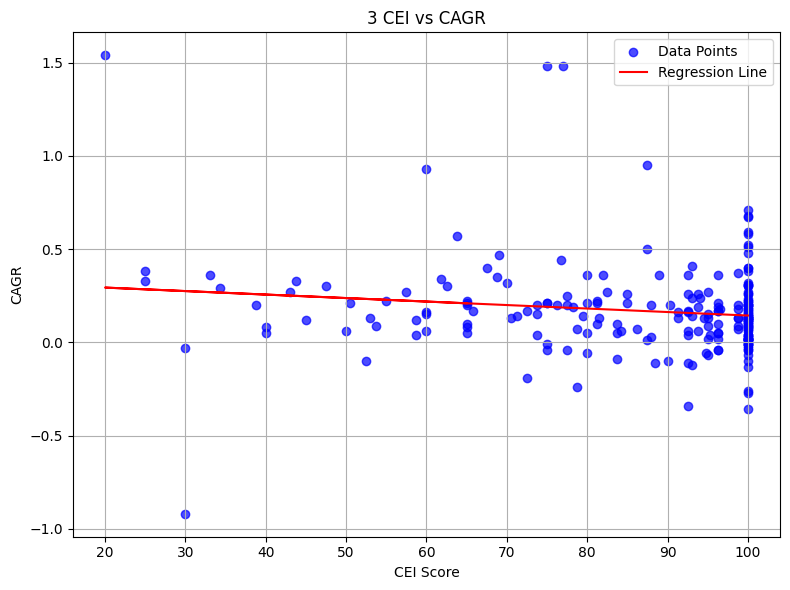


5 Regression:
  Slope:      -0.000858
  Intercept:  0.284134
  R-squared:  0.008474


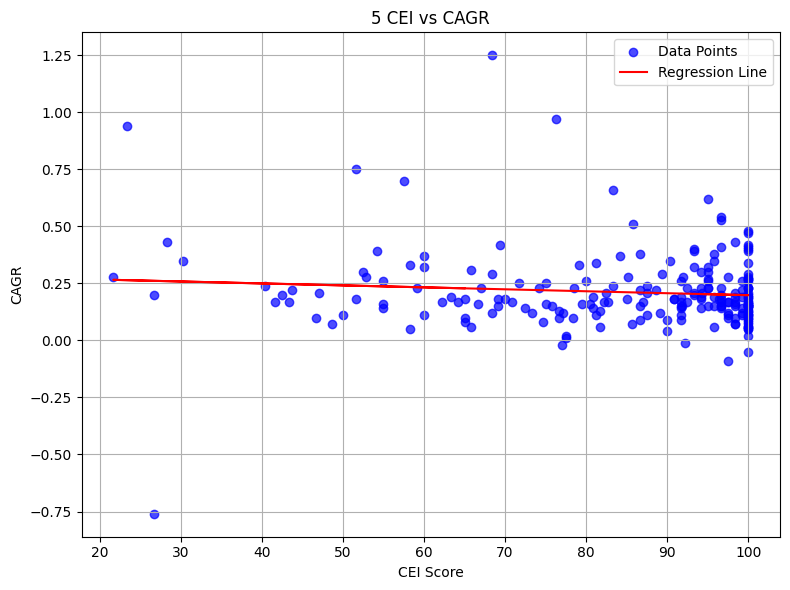


10 Regression:
  Slope:      0.000048
  Intercept:  0.123238
  R-squared:  0.000061


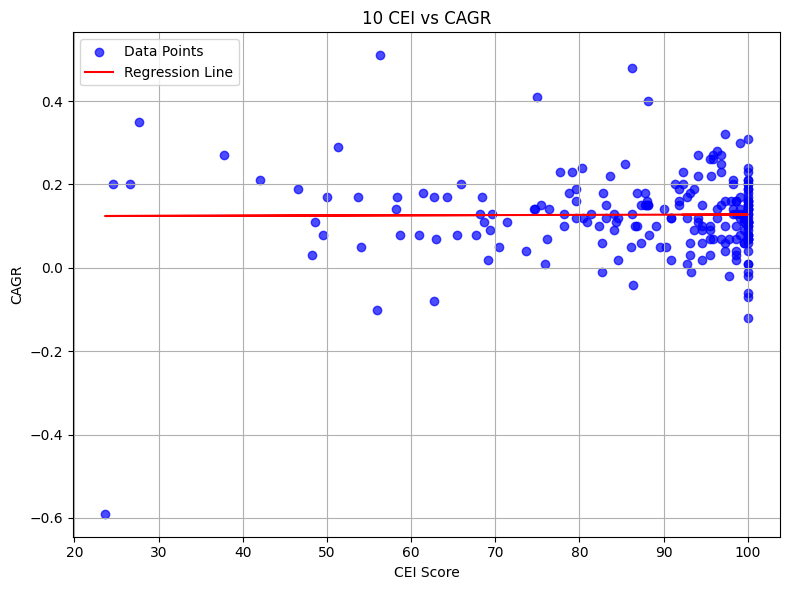


15 Regression:
  Slope:      0.000109
  Intercept:  0.106650
  R-squared:  0.000362


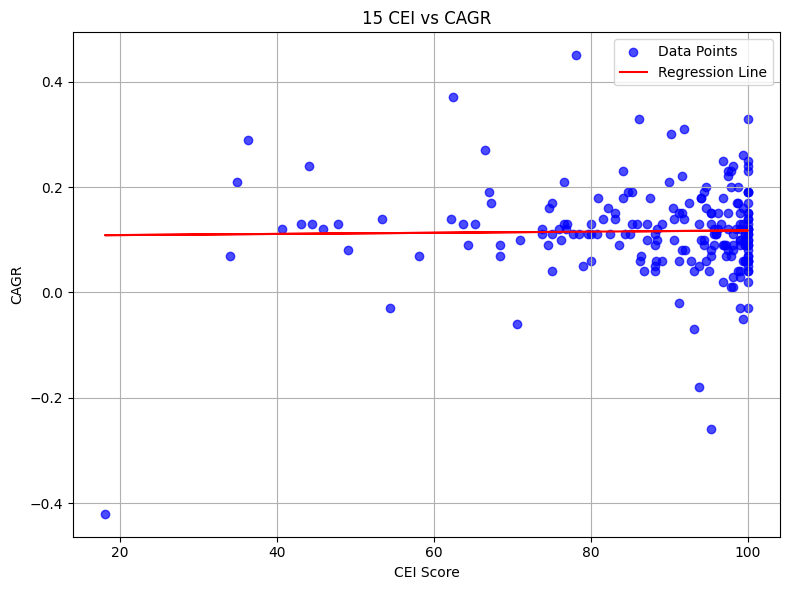


18 Regression:
  Slope:      -0.000744
  Intercept:  0.183726
  R-squared:  0.027389


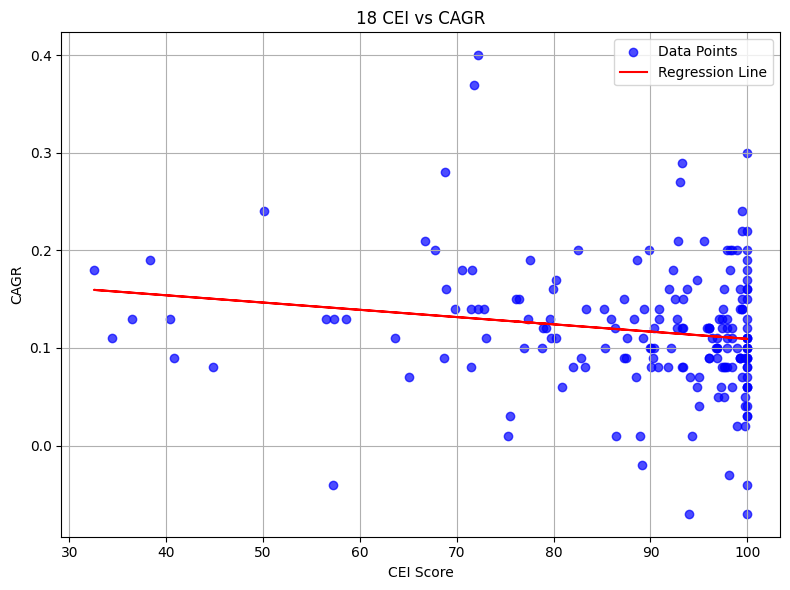

In [ ]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.multitest import multipletests


# Load the Excel file and 'Output' sheet
df = pd.read_csv("Stock price_2005_2025_R1(Output).csv")

# Define CEI and CAGR row names
cei_rows = [
    "3 Year CEI (2008-2011)",
    "5 Year CEI (2008-2013)",
    "10 Year CEI (2008-2018)",
    "15 Year CEI (2008-2023)",
    "18 Year CEI (2008-2026)"
]

cagr_rows = [
    "3 Year CAGR (2008-2011)",
    "5 Year CAGR (2008-2013)",
    "10 Year CAGR (2008-2018)",
    "15 Year CAGR (2008-2023)",
    "18 Year CAGR (2008-2026)"
]

# Loop through each CEI-CAGR pair
for cei_label, cagr_label in zip(cei_rows, cagr_rows):
    # Extract and transpose
    cei = df[df['year'] == cei_label].drop(columns='year').T
    cagr = df[df['year'] == cagr_label].drop(columns='year').T

    # Rename columns
    cei.columns = ['CEI']
    cagr.columns = ['CAGR']

    # Merge and drop rows with 0 or NaN
    data = pd.concat([cei, cagr], axis=1).dropna()

    data['CEI'] = pd.to_numeric(data['CEI'], errors='coerce')
    data['CAGR'] = pd.to_numeric(data['CAGR'], errors='coerce')

    data = data[(data['CEI'] != 0) & (data['CAGR'] != 0) & (data['CAGR'] != -1)]

    # Prepare for regression
    X = data[['CEI']]
    y = data['CAGR']
    model = LinearRegression().fit(X, y)
    y_pred = model.predict(X)

    # Print regression results
    print(f"\n{cei_label.split()[0]} Regression:")
    print(f"  Slope:      {model.coef_[0]:.6f}")
    print(f"  Intercept:  {model.intercept_:.6f}")
    print(f"  R-squared:  {model.score(X, y):.6f}")
    # print(f"  N samples:  {len(data)}")

    # Plot
    plt.figure(figsize=(8, 6))
    plt.scatter(data['CEI'], data['CAGR'], color='blue', alpha=0.7, label='Data Points')
    plt.plot(data['CEI'], y_pred, color='red', label='Regression Line')
    plt.xlabel('CEI Score')
    plt.ylabel('CAGR')
    plt.title(f"{cei_label.split()[0]} CEI vs CAGR")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()



3 Regression:
  Slope:      -0.007789
  Intercept:  1.138937
  R-squared:  0.034952


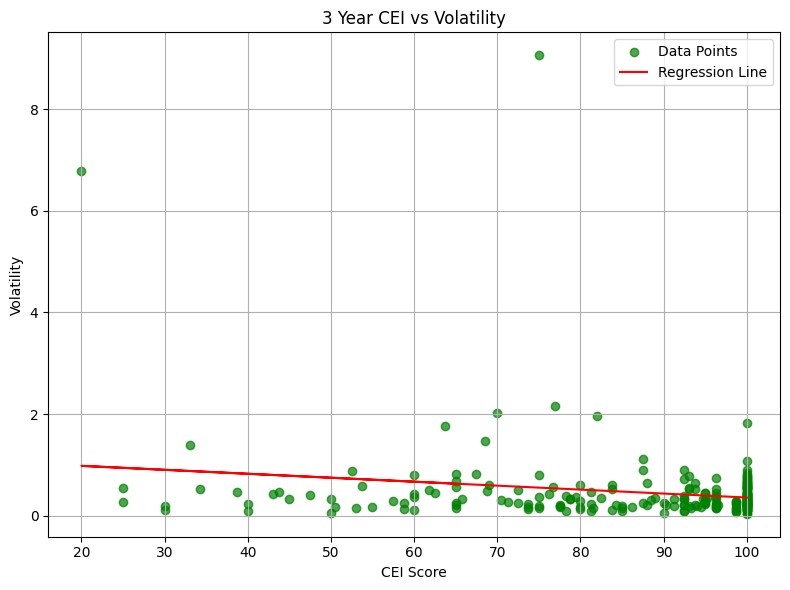


5 Regression:
  Slope:      -0.006057
  Intercept:  0.986847
  R-squared:  0.024095


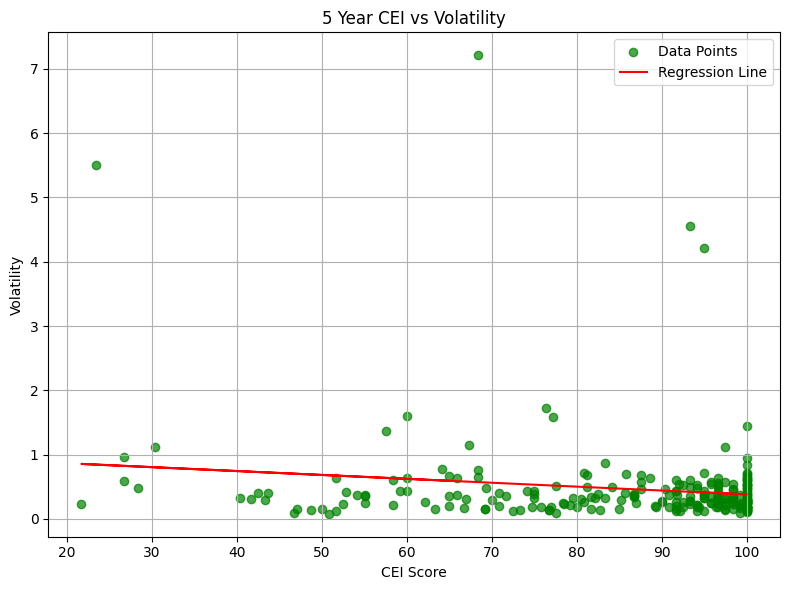


10 Regression:
  Slope:      -0.005403
  Intercept:  0.852593
  R-squared:  0.030682


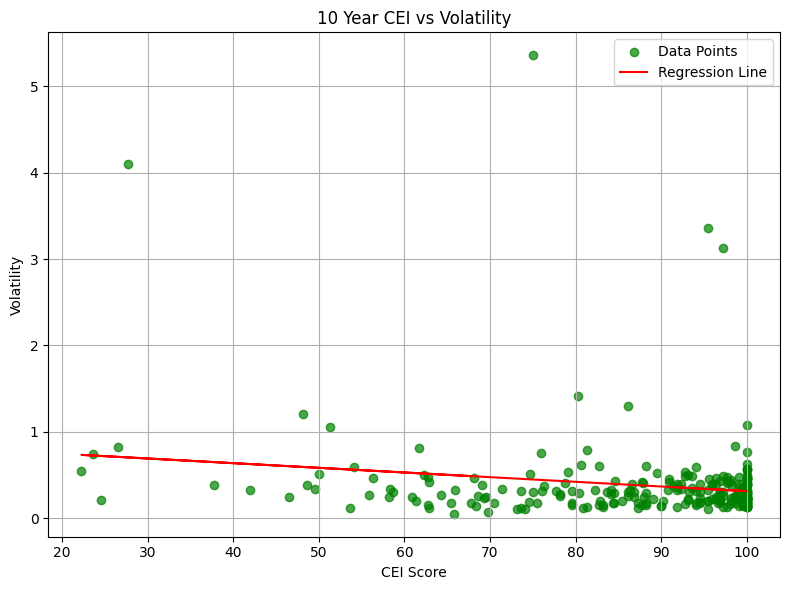


15 Regression:
  Slope:      -0.003151
  Intercept:  0.641568
  R-squared:  0.015772


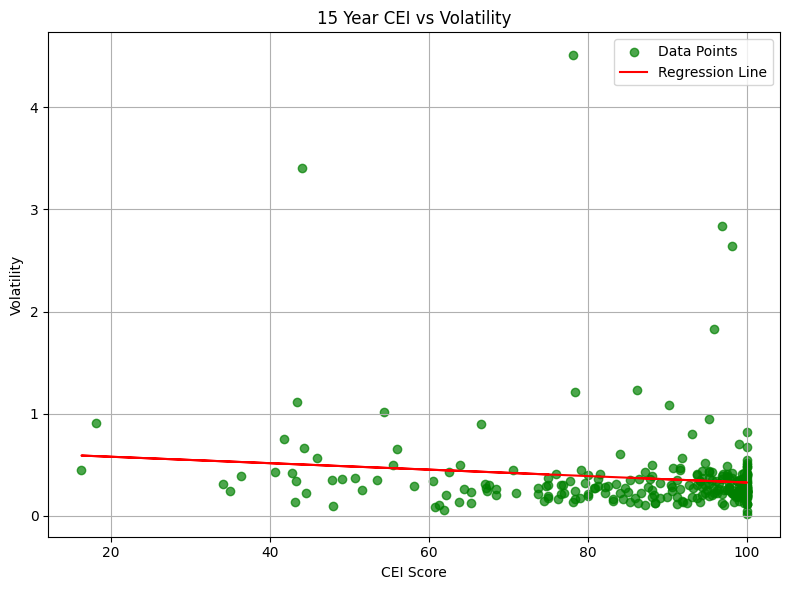


18 Regression:
  Slope:      -0.003728
  Intercept:  0.702676
  R-squared:  0.015689


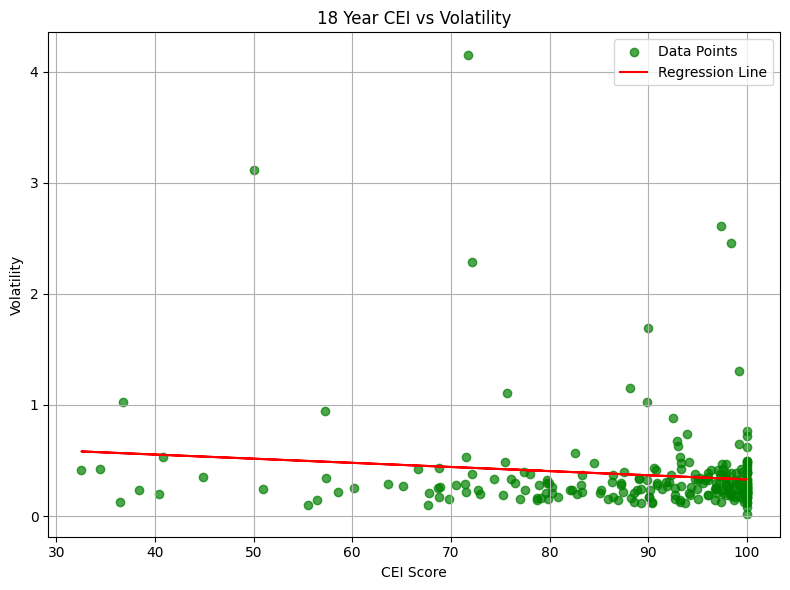

In [44]:
# Load the Excel file and 'Output' sheet
df = pd.read_csv("Stock price_2005_2025_R1(Output).csv")

# Define CEI and Volatility row names
cei_rows = [
    "3 Year CEI (2008-2011)",
    "5 Year CEI (2008-2013)",
    "10 Year CEI (2008-2018)",
    "15 Year CEI (2008-2023)",
    "18 Year CEI (2008-2026)"
]

vol_rows = [
    "3 Year Vol (2008-2011)",
    "5 Year Vol (2008-2013)",
    "10 Year Vol (2008-2018)",
    "15 Year Vol (2008-2023)",
    "18 Year Vol (2008-2026)"
]

# Loop through each CEI-Volatility pair
for cei_label, vol_label in zip(cei_rows, vol_rows):
    # Extract and transpose
    cei = df[df['year'] == cei_label].drop(columns='year').T
    vol = df[df['year'] == vol_label].drop(columns='year').T

    # Rename columns
    cei.columns = ['CEI']
    vol.columns = ['Volatility']

    # Merge and drop rows with 0 or NaN
    data = pd.concat([cei, vol], axis=1).dropna()
    
    data['CEI'] = pd.to_numeric(data['CEI'], errors='coerce')
    data['Volatility'] = pd.to_numeric(data['Volatility'], errors='coerce')

    data = data[(data['CEI'] != 0) & (data['Volatility'] != 0) & (data['Volatility'] != -1)]


    # Prepare for regression
    X = data[['CEI']]
    y = data['Volatility']
    model = LinearRegression().fit(X, y)
    y_pred = model.predict(X)

    # Print regression results
    print(f"\n{cei_label.split()[0]} Regression:")
    print(f"  Slope:      {model.coef_[0]:.6f}")
    print(f"  Intercept:  {model.intercept_:.6f}")
    print(f"  R-squared:  {model.score(X, y):.6f}")
    # print(f"  N samples:  {len(data)}")

    # Plot
    plt.figure(figsize=(8, 6))
    plt.scatter(data['CEI'], data['Volatility'], color='green', alpha=0.7, label='Data Points')
    plt.plot(data['CEI'], y_pred, color='red', label='Regression Line')
    plt.xlabel('CEI Score')
    plt.ylabel('Volatility')
    plt.title(f"{cei_label.split()[0]} Year CEI vs Volatility")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()


In [45]:
# Load the Excel file
df = pd.read_csv("Stock price_2005_2025_R1(Output).csv")

# Extract CEI and CAGR for 15-year
cei = df[df['year'] == "18 Year CEI (2008-2026)"].drop(columns='year').T
cagr = df[df['year'] == "18 Year CAGR (2008-2026)"].drop(columns='year').T

# Rename and merge
cei.columns = ['CEI']
cagr.columns = ['CAGR']
data = pd.concat([cei, cagr], axis=1).dropna()

# Filter out rows with 0
data['CEI'] = pd.to_numeric(data['CEI'], errors='coerce')
data['CAGR'] = pd.to_numeric(data['CAGR'], errors='coerce')

data = data[(data['CEI'] != 0) & (data['CAGR'] != 0) & (data['CAGR'] != -1)]




# Create CEI quartiles
data['CEI_Quartile'] = pd.qcut(data['CEI'], q=4, labels=["Q1", "Q2","Q3","Q4"])

# Compute mean CAGR and count of companies in each quartile
quartile_stats = data.groupby('CEI_Quartile')['CAGR'].agg(['mean', 'count']).reset_index()
quartile_stats.columns = ['CEI_Quartile', 'Mean_CAGR', 'N_Companies']

# Display result
print(quartile_stats)


  CEI_Quartile  Mean_CAGR  N_Companies
0           Q1   0.140851           47
1           Q2   0.116304           46
2           Q3   0.103478           46
3           Q4   0.110851           47


C:\Users\julia\AppData\Local\Temp\ipykernel_96760\3419445263.py:26: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  quartile_stats = data.groupby('CEI_Quartile')['CAGR'].agg(['mean', 'count']).reset_index()


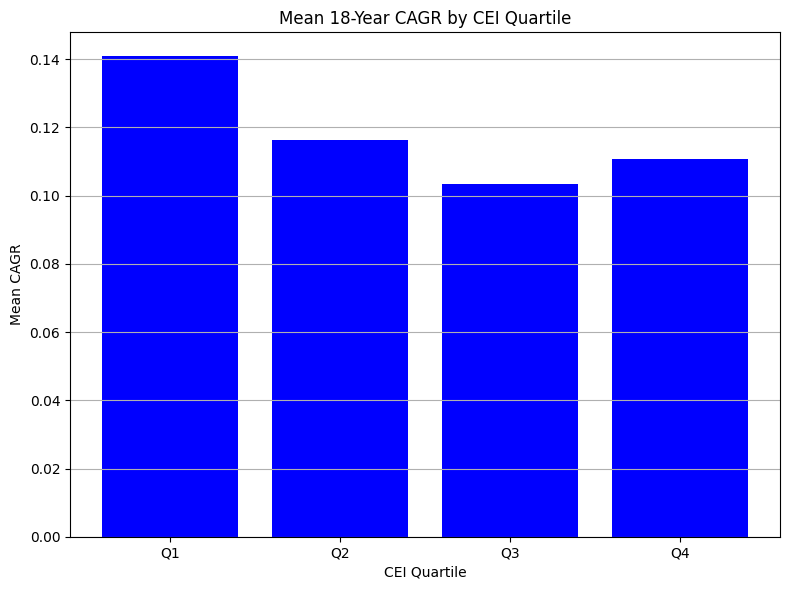

In [46]:
plt.figure(figsize=(8, 6))
plt.bar(quartile_stats['CEI_Quartile'], quartile_stats['Mean_CAGR'], color='blue')
plt.title("Mean 18-Year CAGR by CEI Quartile")
plt.xlabel("CEI Quartile")
plt.ylabel("Mean CAGR")
plt.grid(axis='y')
plt.tight_layout()
plt.show()


In [47]:
data['CEI_Quartile'] = pd.qcut(data['CEI'], q=4, labels=["Q1 (Lowest)", "Q2", "Q3", "Q4 (Highest)"])


In [48]:
quartile_stats = data.groupby('CEI_Quartile')['CAGR'].agg(['mean', 'count']).reset_index()
quartile_stats.columns = ['CEI_Quartile', 'Mean_CAGR', 'N_Companies']
print(quartile_stats.columns)

Index(['CEI_Quartile', 'Mean_CAGR', 'N_Companies'], dtype='object')


C:\Users\julia\AppData\Local\Temp\ipykernel_96760\1221180006.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  quartile_stats = data.groupby('CEI_Quartile')['CAGR'].agg(['mean', 'count']).reset_index()


In [49]:

# Load your Excel file
df = pd.read_csv("Stock price_2005_2025_R1(Output).csv")

# Extract CEI and CAGR for 15-Year
cei = df[df['year'] == "18 Year CEI (2008-2026)"].drop(columns='year').T
cagr = df[df['year'] == "18 Year CAGR (2008-2026)"].drop(columns='year').T

# Rename and merge
cei.columns = ['CEI']
cagr.columns = ['CAGR']
data = pd.concat([cei, cagr], axis=1).dropna()
data['CEI'] = pd.to_numeric(data['CEI'], errors='coerce')
data['CAGR'] = pd.to_numeric(data['CAGR'], errors='coerce')

data = data[(data['CEI'] != 0) & (data['CAGR'] != 0) & (data['CAGR'] != -1)]

# Create CEI quartiles and get bin edges
quartiles, bin_edges = pd.qcut(data['CEI'], q=4, retbins=True, labels=["Q1 (Lowest)", "Q2", "Q3", "Q4 (Highest)"])

# Print quartile CEI ranges
print("\nCEI Quartile Ranges:")
for i in range(len(bin_edges)-1):
    print(f"{quartiles.cat.categories[i]}: {round(bin_edges[i], 2)} to {round(bin_edges[i+1], 2)}")



CEI Quartile Ranges:
Q1 (Lowest): 32.53 to 82.61
Q2: 82.61 to 94.05
Q3: 94.05 to 98.95
Q4 (Highest): 98.95 to 100.0



3 Regression:
  Slope:      0.003797
  Intercept:  0.125328
  R-squared:  0.013724


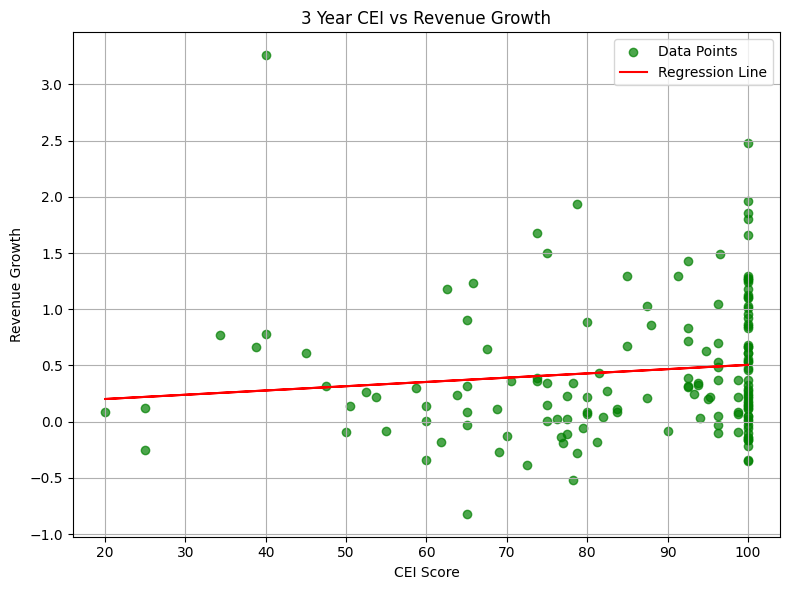


5 Regression:
  Slope:      0.003298
  Intercept:  -0.055900
  R-squared:  0.037248


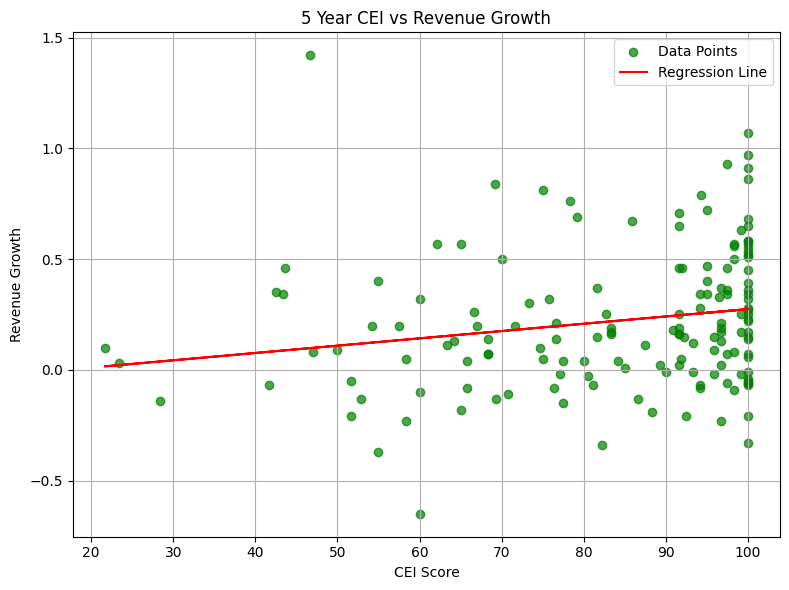


10 Regression:
  Slope:      0.002654
  Intercept:  -0.112893
  R-squared:  0.090538


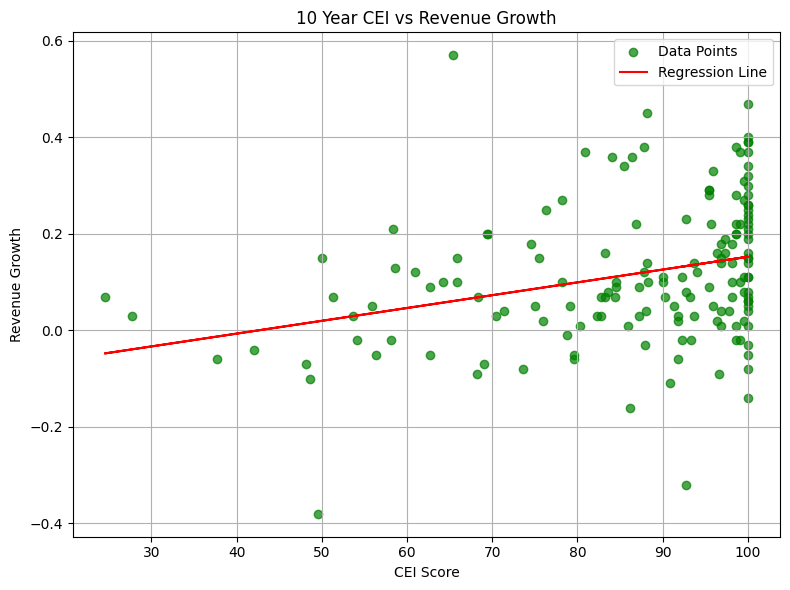


15 Regression:
  Slope:      0.002121
  Intercept:  -0.093504
  R-squared:  0.120087


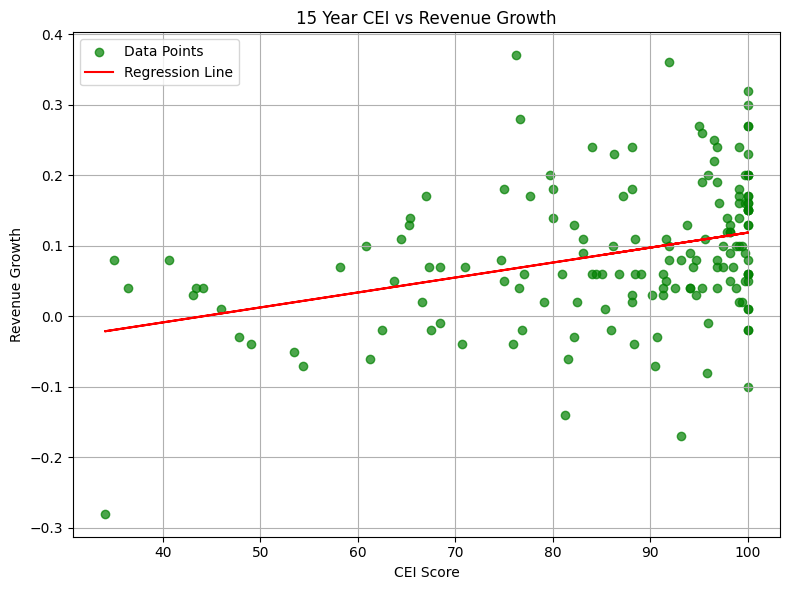


18 Regression:
  Slope:      0.001431
  Intercept:  -0.033773
  R-squared:  0.083602


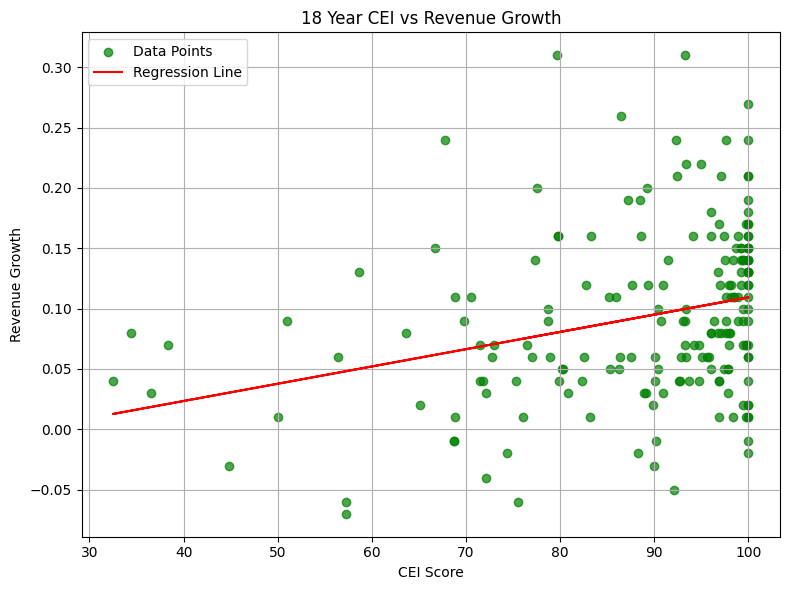

In [50]:

# Load the Excel file and 'Output' sheet
df = pd.read_csv("Stock price_2005_2025_R1(Output).csv")

# Define CEI and Revenue Growth row names
cei_rows = [
    "3 Year CEI (2008-2011)",
    "5 Year CEI (2008-2013)",
    "10 Year CEI (2008-2018)",
    "15 Year CEI (2008-2023)",
    "18 Year CEI (2008-2026)"
]

revenue_rows = [
    "Revenue Growth (2008-2011)",
    "Revenue Growth (2008-2013)",
    "Revenue Growth (2008-2018)",
    "Revenue Growth (2008-2023)",
    "Revenue Growth (2008-2026)"
]

# Loop through each CEI-Revenue Growth pair
for cei_label, revenue_label in zip(cei_rows, revenue_rows):
    # Extract and transpose
    cei = df[df['year'] == cei_label].drop(columns='year').T
    revenue = df[df['year'] == revenue_label].drop(columns='year').T

    # Rename columns
    cei.columns = ['CEI']
    revenue.columns = ['Revenue_Growth']

    # Merge and drop rows with -1, 0 or NaN
    data = pd.concat([cei, revenue], axis=1).dropna()

    data['CEI'] = pd.to_numeric(data['CEI'], errors='coerce')
    data['Revenue_Growth'] = pd.to_numeric(data['Revenue_Growth'], errors='coerce')

    data = data[(data['CEI'] != 0) & (data['CEI'] != -1) & (data['Revenue_Growth'] != 0) & (data['Revenue_Growth'] != -1)]


    

    # Prepare for regression
    X = data[['CEI']]
    y = data['Revenue_Growth']
    model = LinearRegression().fit(X, y)
    y_pred = model.predict(X)

    # Print regression results
    print(f"\n{cei_label.split()[0]} Regression:")
    print(f"  Slope:      {model.coef_[0]:.6f}")
    print(f"  Intercept:  {model.intercept_:.6f}")
    print(f"  R-squared:  {model.score(X, y):.6f}")
    # print(f"  N samples:  {len(data)}")

    # Plot
    plt.figure(figsize=(8, 6))
    plt.scatter(data['CEI'], data['Revenue_Growth'], color='green', alpha=0.7, label='Data Points')
    plt.plot(data['CEI'], y_pred, color='red', label='Regression Line')
    plt.xlabel('CEI Score')
    plt.ylabel('Revenue Growth')
    plt.title(f"{cei_label.split()[0]} Year CEI vs Revenue Growth")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [51]:


# Load the Excel file
df = pd.read_csv("Stock price_2005_2025_R1(Output).csv")

# Extract CEI and Revenue Growth for 15-year
cei = df[df['year'] == "18 Year CEI (2008-2026)"].drop(columns='year').T
revenue = df[df['year'] == "Revenue Growth (2008-2026)"].drop(columns='year').T

# Rename and merge
cei.columns = ['CEI']
revenue.columns = ['Revenue_Growth']
data = pd.concat([cei, revenue], axis=1).dropna()
data['CEI'] = pd.to_numeric(data['CEI'], errors='coerce')
data['Revenue_Growth'] = pd.to_numeric(data['Revenue_Growth'], errors='coerce')

# Filter out rows with 0 and -1
data = data[(data['CEI'] != 0) & (data['Revenue_Growth'] != 0) & (data['Revenue_Growth'] != -1)]

# Create CEI quartiles
data['CEI_Quartile'] = pd.qcut(data['CEI'], q=4, labels=["Q1 (Lowest)", "Q2", "Q3", "Q4 (Highest)"])

# Compute mean Revenue Growth and count of companies in each quartile
quartile_stats = data.groupby('CEI_Quartile')['Revenue_Growth'].agg(['mean', 'count']).reset_index()
quartile_stats.columns = ['CEI_Quartile', 'Mean_Revenue_Growth', 'N_Companies']

# Display result
print(quartile_stats)

   CEI_Quartile  Mean_Revenue_Growth  N_Companies
0   Q1 (Lowest)             0.062500           48
1            Q2             0.093830           47
2            Q3             0.104898           49
3  Q4 (Highest)             0.112609           46


C:\Users\julia\AppData\Local\Temp\ipykernel_96760\2314924713.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  quartile_stats = data.groupby('CEI_Quartile')['Revenue_Growth'].agg(['mean', 'count']).reset_index()


In [52]:
import pandas as pd

# Load the Excel file
df = pd.read_csv("Stock price_2005_2025_R1(Output).csv")

# Extract CEI and Revenue Growth for 15-year
cei = df[df['year'] == "18 Year CEI (2008-2026)"].drop(columns='year').T
revenue = df[df['year'] == "Revenue Growth (2008-2026)"].drop(columns='year').T

# Rename and merge
cei.columns = ['CEI']
revenue.columns = ['Revenue_Growth']
data = pd.concat([cei, revenue], axis=1).dropna()
data['CEI'] = pd.to_numeric(data['CEI'], errors='coerce')
data['Revenue_Growth'] = pd.to_numeric(data['Revenue_Growth'], errors='coerce')

# Set index as company name
data.index.name = 'Company'

# Filter out invalid rows
data = data[(data['CEI'] != 0) & (data['Revenue_Growth'] != 0) & (data['Revenue_Growth'] != -1)]

# Create CEI quartiles
data['CEI_Quartile'] = pd.qcut(data['CEI'], q=4, labels=["Q1 (Lowest)", "Q2", "Q3", "Q4 (Highest)"])

# Get companies in bottom and top quartiles
bottom_quartile = data[data['CEI_Quartile'] == "Q1 (Lowest)"].index.tolist()
top_quartile = data[data['CEI_Quartile'] == "Q4 (Highest)"].index.tolist()

# Print counts
print(f"Count of Companies in Bottom Quartile (Q1): {len(bottom_quartile)}")
print(f"Count of Companies in Top Quartile (Q4): {len(top_quartile)}")

# Print companies in bottom vs top quartile
print("\nBottom Quartile (Q1) vs Top Quartile (Q4):")
print("\n{:<30} {:<30}".format("Bottom Quartile (Q1)", "Top Quartile (Q4)"))
print("-" * 60)
max_len = max(len(bottom_quartile), len(top_quartile))
for i in range(max_len):
    bottom = bottom_quartile[i] if i < len(bottom_quartile) else ""
    top = top_quartile[i] if i < len(top_quartile) else ""
    print("{:<30} {:<30}".format(bottom, top))

# Create a DataFrame for CSV output
csv_data = pd.DataFrame({
    'Bottom Quartile (Q1)': pd.Series(bottom_quartile),
    'Top Quartile (Q4)': pd.Series(top_quartile)
})

# Save to CSV
csv_data.to_csv('quartile_comparison.csv', index=False)
print("\nData saved to 'quartile_comparison.csv'")

Count of Companies in Bottom Quartile (Q1): 48
Count of Companies in Top Quartile (Q4): 46

Bottom Quartile (Q1) vs Top Quartile (Q4):

Bottom Quartile (Q1)           Top Quartile (Q4)             
------------------------------------------------------------
A                              AAL                           
AFG                            AAPL                          
AVT                            ACN                           
AZO                            ANF                           
BALL                           AON                           
BAX                            AXP                           
BRDCY                          BMY                           
CAR                            C                             
CAT                            CMI                           
CBRL                           COF                           
CEG                            CSCO                          
CM                             CVX                         

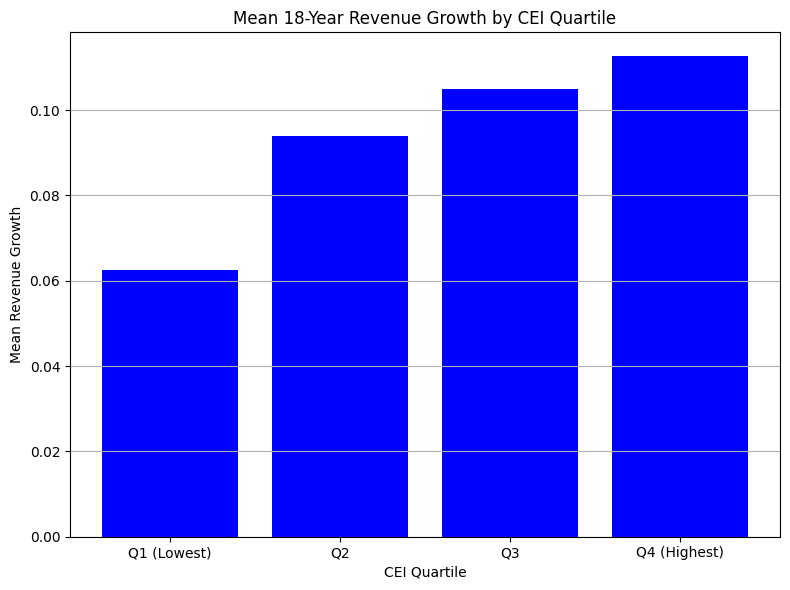

In [53]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.bar(quartile_stats['CEI_Quartile'], quartile_stats['Mean_Revenue_Growth'], color='blue')
plt.title("Mean 18-Year Revenue Growth by CEI Quartile")
plt.xlabel("CEI Quartile")
plt.ylabel("Mean Revenue Growth")
plt.grid(axis='y')
plt.tight_layout()
plt.show()

C:\Users\julia\AppData\Local\Temp\ipykernel_96760\1381459193.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  quartile_ranges = data.groupby('CEI_Quartile')['CEI'].agg(['min', 'max']).reset_index()


CEI Quartile Ranges:
Q1 (Lowest): 32.5 - 82.5
Q2: 82.8 - 94.8
Q3: 94.8 - 99.2
Q4 (Highest): 99.4 - 100.0


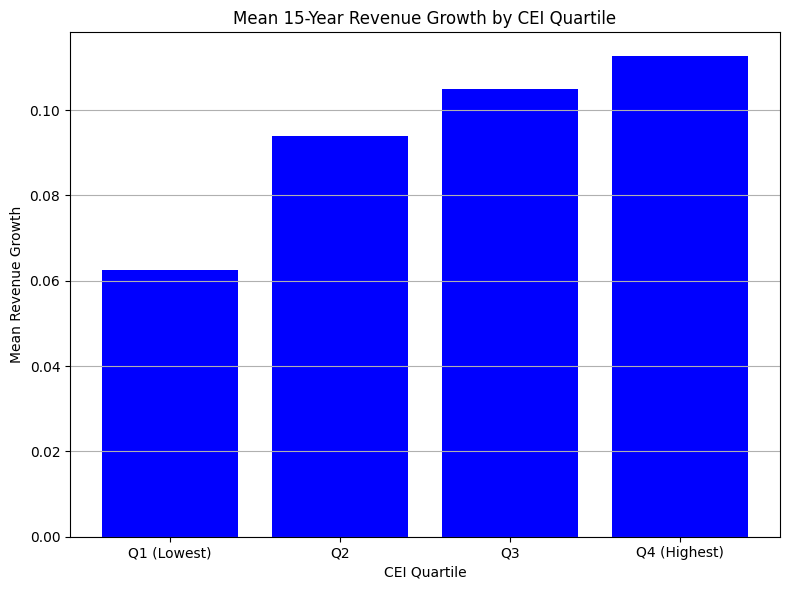

In [54]:

# Calculate CEI quartile ranges
quartile_ranges = data.groupby('CEI_Quartile')['CEI'].agg(['min', 'max']).reset_index()
print("CEI Quartile Ranges:")
for _, row in quartile_ranges.iterrows():
    print(f"{row['CEI_Quartile']}: {row['min']:.1f} - {row['max']:.1f}")

plt.figure(figsize=(8, 6))
plt.bar(quartile_stats['CEI_Quartile'], quartile_stats['Mean_Revenue_Growth'], color='blue')
plt.title("Mean 15-Year Revenue Growth by CEI Quartile")
plt.xlabel("CEI Quartile")
plt.ylabel("Mean Revenue Growth")
plt.grid(axis='y')
plt.tight_layout()
plt.show()


3 Regression:
  Slope:      105227926.694489
  Intercept:  -1275552044.495923
  R-squared:  0.018363


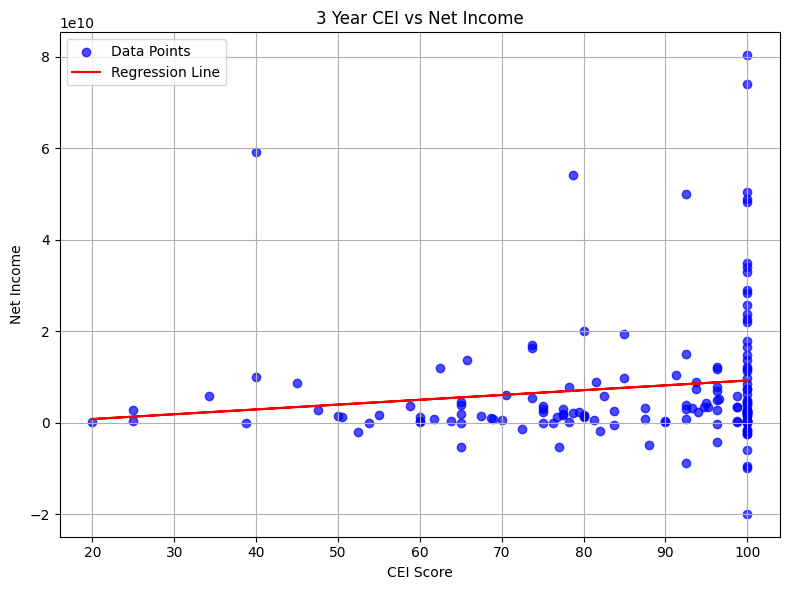


5 Regression:
  Slope:      216780858.268880
  Intercept:  -5252496148.738960
  R-squared:  0.028476


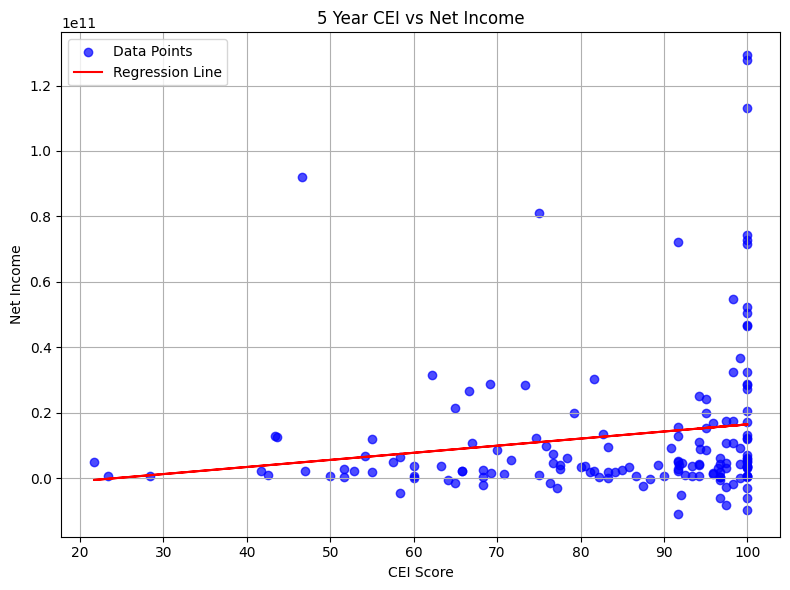


10 Regression:
  Slope:      596403103.242114
  Intercept:  -25850295520.483868
  R-squared:  0.046009


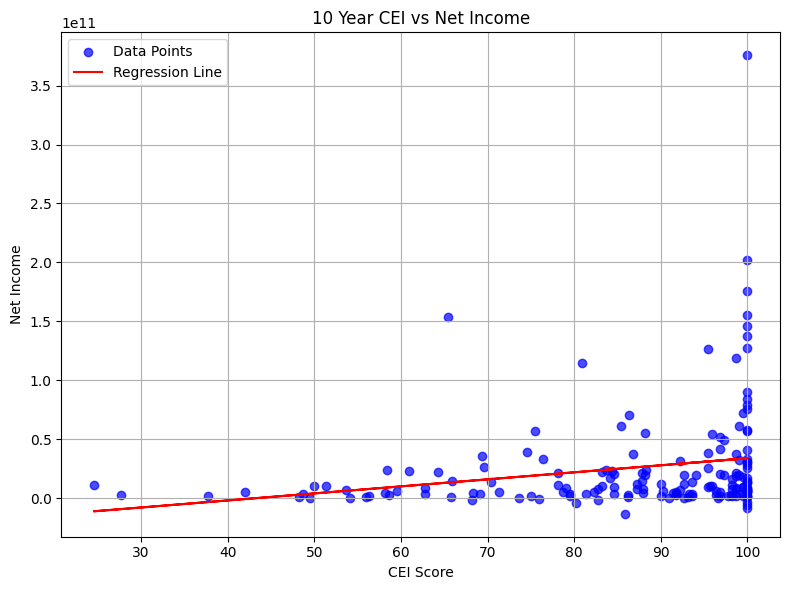


15 Regression:
  Slope:      1303701374.628452
  Intercept:  -67676547995.032066
  R-squared:  0.058036


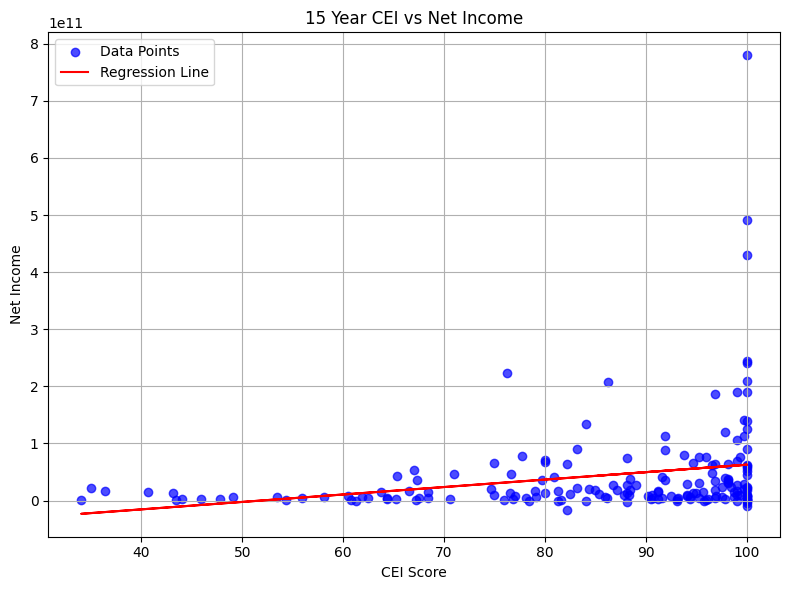


18 Regression:
  Slope:      1426476014.262878
  Intercept:  -72959867561.020798
  R-squared:  0.049615


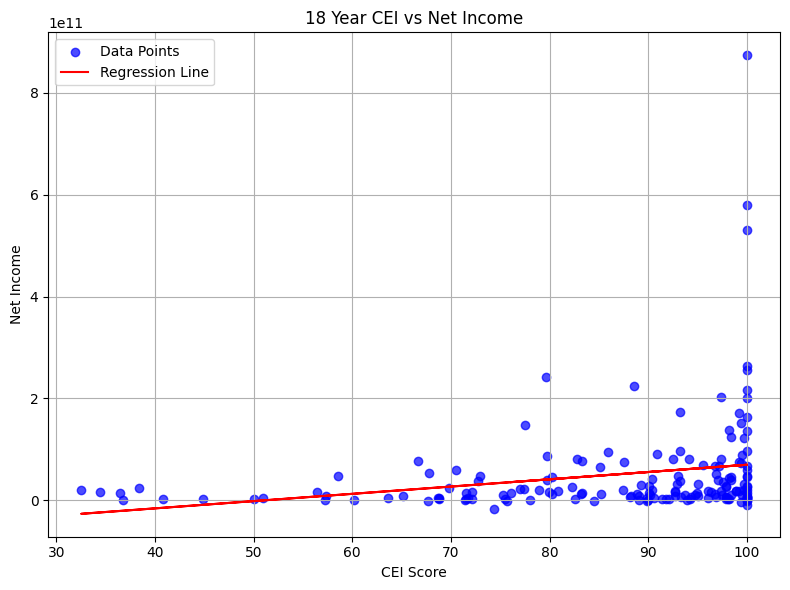

In [55]:


# Load the Excel file and specify the correct sheet
df = pd.read_csv("Stock price_2005_2025_R1(Output).csv")

# Ensure the first column is labeled 'year'
df.columns = ['year'] + list(df.columns[1:])

# Define CEI and Net Income row labels
cei_rows = [
    "3 Year CEI (2008-2011)",
    "5 Year CEI (2008-2013)",
    "10 Year CEI (2008-2018)",
    "15 Year CEI (2008-2023)",
    "18 Year CEI (2008-2026)"
]

net_income_rows = [
    "Net Income (2008-2011)",
    "Net Income (2008-2013)",
    "Net Income (2008-2018)",
    "Net Income (2008-2023)",
    "Net Income (2008-onwards)"
]

# Loop through CEI–Net Income pairs
for cei_label, income_label in zip(cei_rows, net_income_rows):
    # Fetch the CEI and Net Income rows
    cei_row = df[df['year'] == cei_label]
    income_row = df[df['year'] == income_label]

    # Check if both rows exist
    if cei_row.empty or income_row.empty:
        print(f"Skipping pair: '{cei_label}' or '{income_label}' not found in 'year' column.")
        continue

    # Transpose and reset index
    cei = cei_row.drop(columns='year').T.reset_index(drop=True)
    net_income = income_row.drop(columns='year').T.reset_index(drop=True)

    # Rename columns
    cei.columns = ['CEI']
    net_income.columns = ['Net_Income']

    # Merge and clean
    data = pd.concat([cei, net_income], axis=1).dropna()
    data['CEI'] = pd.to_numeric(data['CEI'], errors='coerce')
    data['Net_Income'] = pd.to_numeric(data['Net_Income'], errors='coerce')
    data = data[(data['CEI'] != 0) & (data['CEI'] != -1) & (data['Net_Income'] != 0) & (data['Net_Income'] != -1)]


    if data.empty:
        print(f"Skipping pair: '{cei_label}' vs '{income_label}' — no valid numeric data after filtering.")
        continue

    # Linear regression
    X = data[['CEI']]
    y = data['Net_Income']
    model = LinearRegression().fit(X, y)
    y_pred = model.predict(X)

    # Print results
    print(f"\n{cei_label.split()[0]} Regression:")
    print(f"  Slope:      {model.coef_[0]:.6f}")
    print(f"  Intercept:  {model.intercept_:.6f}")
    print(f"  R-squared:  {model.score(X, y):.6f}")
    # print(f"  N samples:  {len(data)}")

    # Plot
    plt.figure(figsize=(8, 6))
    plt.scatter(data['CEI'], data['Net_Income'], color='blue', alpha=0.7, label='Data Points')
    plt.plot(data['CEI'], y_pred, color='red', label='Regression Line')
    plt.xlabel('CEI Score')
    plt.ylabel('Net Income')
    plt.title(f"{cei_label.split()[0]} Year CEI vs Net Income")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()



   CEI_Quartile  Mean_Net_Income  N_Companies
0   Q1 (Lowest)     1.777591e+10           42
1            Q2     3.653617e+10           43
2            Q3     4.020426e+10           41
3  Q4 (Highest)     1.078360e+11           42


C:\Users\julia\AppData\Local\Temp\ipykernel_96760\3167051941.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  quartile_stats = data.groupby('CEI_Quartile')['Net_Income'].agg(['mean', 'count']).reset_index()


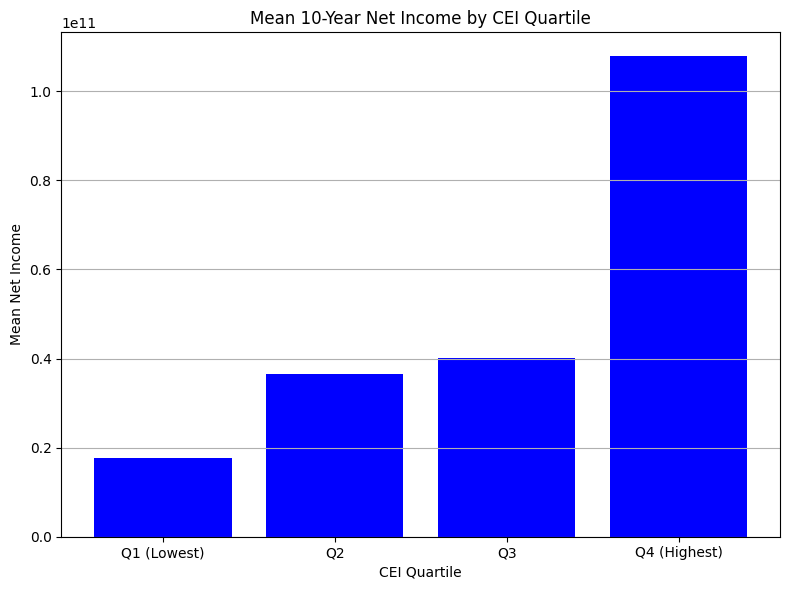

In [56]:

# Load the Excel file
df = pd.read_csv("Stock price_2005_2025_R1(Output).csv")

# Extract CEI and Net Income for 10-year horizon
cei = df[df['year'] == "18 Year CEI (2008-2026)"].drop(columns='year').T
net_income = df[df['year'] == "Net Income (2008-onwards)"].drop(columns='year').T

# Rename and merge
cei.columns = ['CEI']
net_income.columns = ['Net_Income']
data = pd.concat([cei, net_income], axis=1).dropna()
data['CEI'] = pd.to_numeric(data['CEI'], errors='coerce')
data['Net_Income'] = pd.to_numeric(data['Net_Income'], errors='coerce')
# Filter out rows with 0 and -1
data = data[(data['CEI'] != 0) & (data['Net_Income'] != 0) & (data['Net_Income'] != -1)]

# Create CEI quartiles
data['CEI_Quartile'] = pd.qcut(data['CEI'], q=4, labels=["Q1 (Lowest)", "Q2", "Q3", "Q4 (Highest)"])

# Compute mean Net Income and count of companies in each quartile
quartile_stats = data.groupby('CEI_Quartile')['Net_Income'].agg(['mean', 'count']).reset_index()
quartile_stats.columns = ['CEI_Quartile', 'Mean_Net_Income', 'N_Companies']

# Display result
print(quartile_stats)

# Bar chart
plt.figure(figsize=(8, 6))
plt.bar(quartile_stats['CEI_Quartile'], quartile_stats['Mean_Net_Income'], color='blue')
plt.title("Mean 10-Year Net Income by CEI Quartile")
plt.xlabel("CEI Quartile")
plt.ylabel("Mean Net Income")
plt.grid(axis='y')
plt.tight_layout()
plt.show()



3 Regression:
  Slope:      155871656.682807
  Intercept:  25286106760.754883
  R-squared:  0.002342


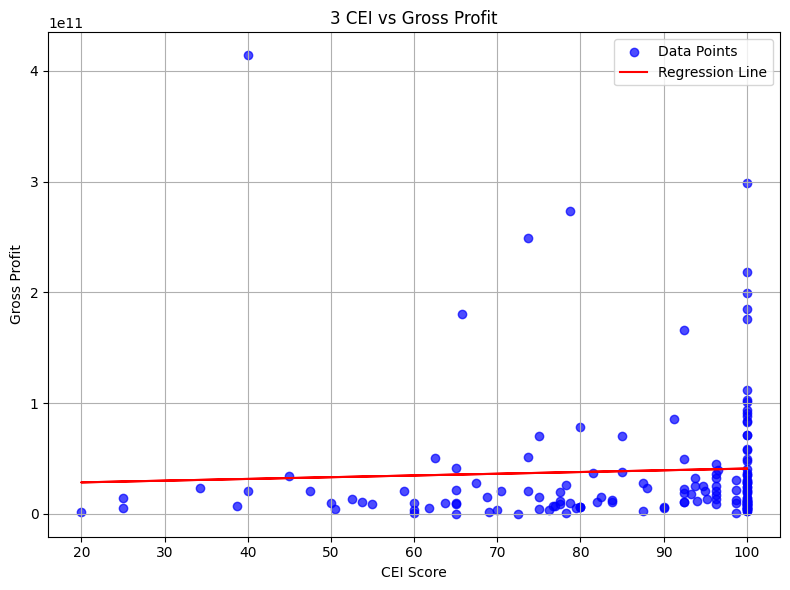


5 Regression:
  Slope:      381591245.513487
  Intercept:  27615308629.103874
  R-squared:  0.005718


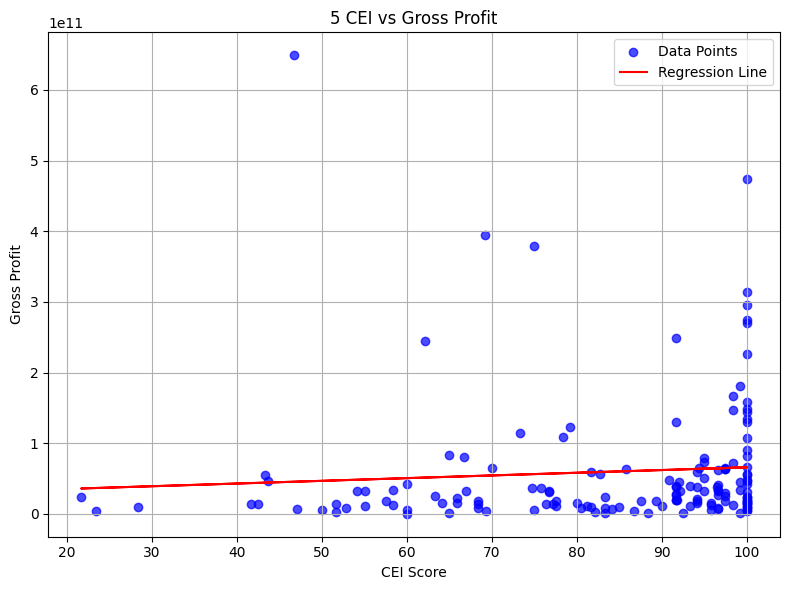


10 Regression:
  Slope:      1681410170.744678
  Intercept:  -31441871701.053421
  R-squared:  0.025002


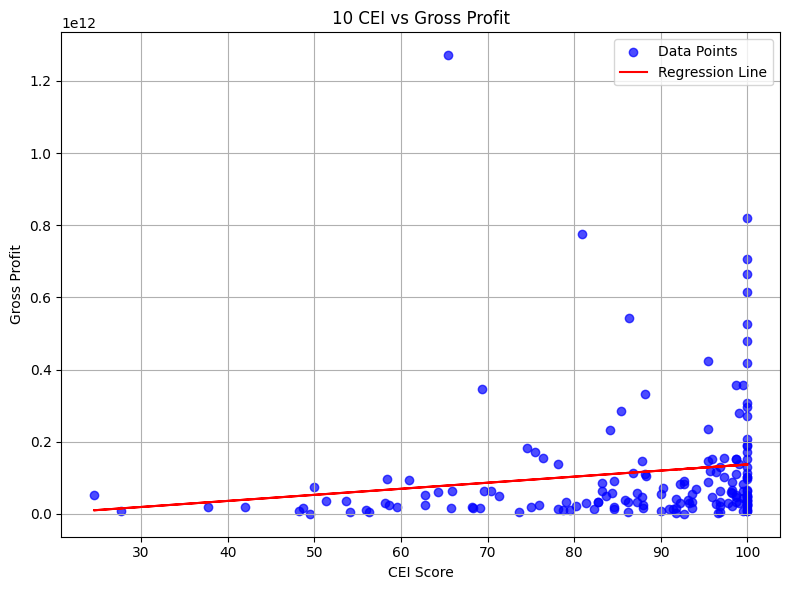


15 Regression:
  Slope:      4171611395.035644
  Intercept:  -177273638996.526398
  R-squared:  0.053820


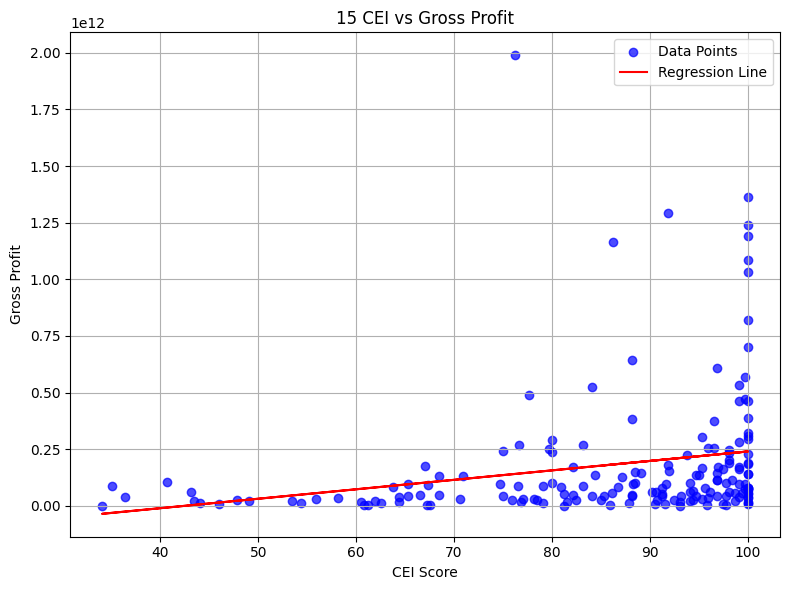


18 Regression:
  Slope:      4492965694.239188
  Intercept:  -183847381524.926544
  R-squared:  0.046384


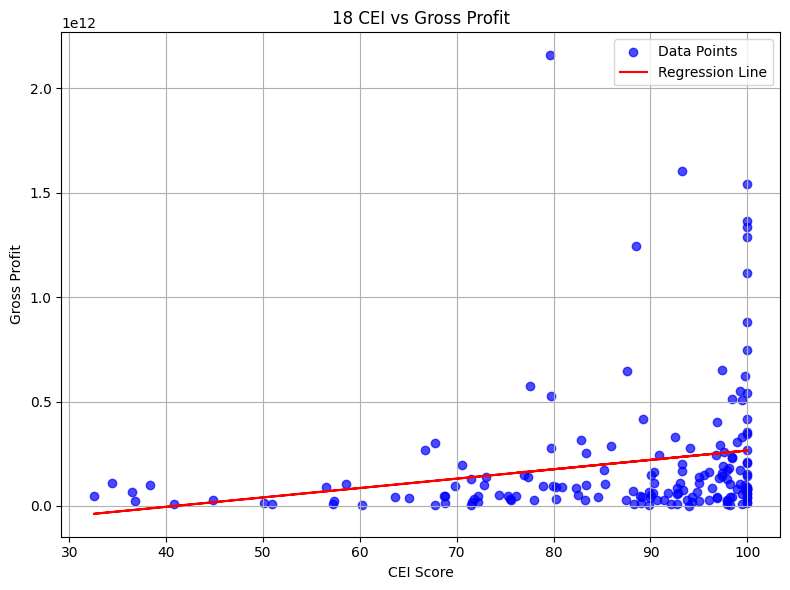

In [57]:

# Load the Excel file and specify the correct sheet
df = pd.read_csv("Stock price_2005_2025_R1(Output).csv")

# Ensure the first column is labeled 'year'
df.columns = ['year'] + list(df.columns[1:])

# Define CEI and Gross Profit row labels
cei_rows = [
    "3 Year CEI (2008-2011)",
    "5 Year CEI (2008-2013)",
    "10 Year CEI (2008-2018)",
    "15 Year CEI (2008-2023)",
    "18 Year CEI (2008-2026)"
]

gross_profit_rows = [
    "Gross Profit (2008-2011)",
    "Gross Profit (2008-2013)",
    "Gross Profit (2008-2018)",
    "Gross Profit (2008-2023)",
    "Gross Profit (2008-onwards)"
]

# Loop through CEI–Gross Profit pairs
for cei_label, profit_label in zip(cei_rows, gross_profit_rows):
    # Fetch the CEI and Gross Profit rows
    cei_row = df[df['year'] == cei_label]
    profit_row = df[df['year'] == profit_label]

    # Check if both rows exist
    if cei_row.empty or profit_row.empty:
        print(f"Skipping pair: '{cei_label}' or '{profit_label}' not found in 'year' column.")
        continue

    # Transpose and reset index
    cei = cei_row.drop(columns='year').T.reset_index(drop=True)
    gross_profit = profit_row.drop(columns='year').T.reset_index(drop=True)

    # Rename columns
    cei.columns = ['CEI']
    gross_profit.columns = ['Gross_Profit']

    # Merge and clean
    data = pd.concat([cei, gross_profit], axis=1).dropna()
    data['CEI'] = pd.to_numeric(data['CEI'], errors='coerce')
    data['Gross_Profit'] = pd.to_numeric(data['Gross_Profit'], errors='coerce')
    data = data[(data['CEI'] != 0) & (data['CEI'] != -1) & (data['Gross_Profit'] != 0) & (data['Gross_Profit'] != -1)]

    if data.empty:
        print(f"Skipping pair: '{cei_label}' vs '{profit_label}' — no valid numeric data after filtering.")
        continue

    # Linear regression
    X = data[['CEI']]
    y = data['Gross_Profit']
    model = LinearRegression().fit(X, y)
    y_pred = model.predict(X)

    # Print results
    print(f"\n{cei_label.split()[0]} Regression:")
    print(f"  Slope:      {model.coef_[0]:.6f}")
    print(f"  Intercept:  {model.intercept_:.6f}")
    print(f"  R-squared:  {model.score(X, y):.6f}")
    # print(f"  N samples:  {len(data)}")

    # Plot
    plt.figure(figsize=(8, 6))
    plt.scatter(data['CEI'], data['Gross_Profit'], color='blue', alpha=0.7, label='Data Points')
    plt.plot(data['CEI'], y_pred, color='red', label='Regression Line')
    plt.xlabel('CEI Score')
    plt.ylabel('Gross Profit')
    plt.title(f"{cei_label.split()[0]} CEI vs Gross Profit")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [58]:


# Load the Excel file
df = pd.read_csv("Stock price_2005_2025_R1(Output).csv")

# Extract CEI and Gross Profit for 10-year
cei = df[df['year'] == "18 Year CEI (2008-2026)"].drop(columns='year').T
gross_profit = df[df['year'] == "Gross Profit (2008-onwards)"].drop(columns='year').T

# Rename and merge
cei.columns = ['CEI']
gross_profit.columns = ['Gross_Profit']
data = pd.concat([cei, gross_profit], axis=1).dropna()

# Filter out rows with 0 and -1
data['CEI'] = pd.to_numeric(data['CEI'], errors='coerce')
data['Gross_Profit'] = pd.to_numeric(data['Gross_Profit'], errors='coerce')
data = data[(data['CEI'] != 0) & (data['Gross_Profit'] != 0) & (data['Gross_Profit'] != -1)]

# Create CEI quartiles
data['CEI_Quartile'] = pd.qcut(data['CEI'], q=4, labels=["Q1 (Lowest)", "Q2", "Q3", "Q4 (Highest)"])

# Compute mean Gross Profit and count of companies in each quartile
quartile_stats = data.groupby('CEI_Quartile')['Gross_Profit'].agg(['mean', 'count']).reset_index()
quartile_stats.columns = ['CEI_Quartile', 'Mean_Gross_Profit', 'N_Companies']

# Display result
print(quartile_stats)

   CEI_Quartile  Mean_Gross_Profit  N_Companies
0   Q1 (Lowest)       8.069484e+10           42
1            Q2       2.031211e+11           43
2            Q3       1.744731e+11           41
3  Q4 (Highest)       3.643280e+11           41


C:\Users\julia\AppData\Local\Temp\ipykernel_96760\1114688461.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  quartile_stats = data.groupby('CEI_Quartile')['Gross_Profit'].agg(['mean', 'count']).reset_index()


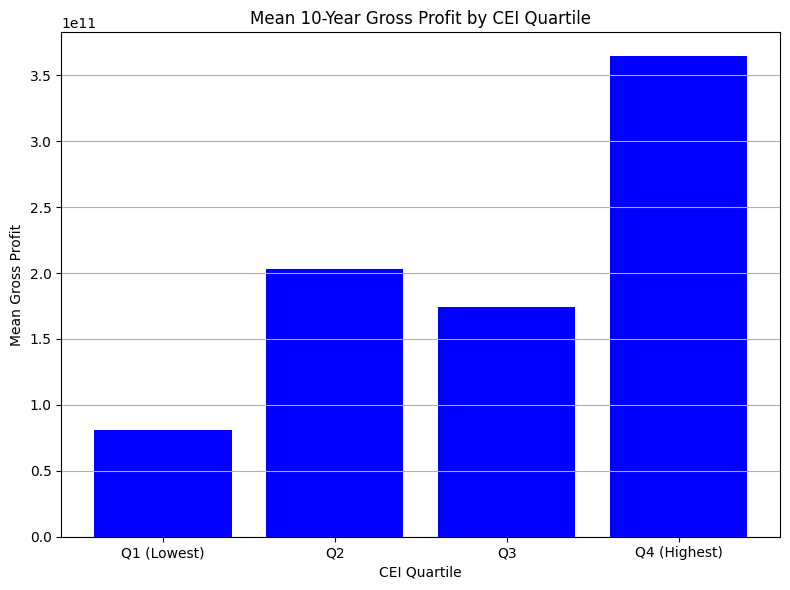

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.bar(quartile_stats['CEI_Quartile'], quartile_stats['Mean_Gross_Profit'], color='blue')
plt.title("Mean 10-Year Gross Profit by CEI Quartile")
plt.xlabel("CEI Quartile")
plt.ylabel("Mean Gross Profit")
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [60]:
"""
import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# Load the Excel file
df = pd.read_excel("Test.xlsx")

# Ensure the first column is labeled 'year'
df.columns = ['year'] + list(df.columns[1:])

# Define CEI and Return on Equity (ROE) row labels
cei_rows = [
    "3 Year CEI (2008-2011)",
    "5 Year CEI(2008-2013)",
    "10 Year CEI (2008-2018)",
    "15 Year CEI (2008-2023)"
]

roe_rows = [
    "Return on Equity (2008-2011)",
    "Return on Equity (2008-2013)",
    "Return on Equity (2008-2018)",
    "Return on Equity (2008-2023)"
]

# Loop through CEI–ROE pairs
for cei_label, roe_label in zip(cei_rows, roe_rows):
    # Fetch CEI and ROE rows
    cei_row = df[df['year'] == cei_label]
    roe_row = df[df['year'] == roe_label]

    # Check if both rows exist
    if cei_row.empty or roe_row.empty:
        print(f"Skipping pair: '{cei_label}' or '{roe_label}' not found in 'year' column.")
        continue

    # Transpose and reset index
    cei = cei_row.drop(columns='year').T.reset_index(drop=True)
    roe = roe_row.drop(columns='year').T.reset_index(drop=True)

    # Rename columns
    cei.columns = ['CEI']
    roe.columns = ['ROE']

    # Merge and clean
    data = pd.concat([cei, roe], axis=1).dropna()
    data = data[(data['CEI'] != 0) & (data['CEI'] != -1) & (data['ROE'] != 0) & (data['ROE'] != -1)]

    if data.empty:
        print(f"Skipping pair: '{cei_label}' vs '{roe_label}' — no valid numeric data after filtering.")
        continue

    # Linear regression
    X = data[['CEI']]
    y = data['ROE']
    model = LinearRegression().fit(X, y)
    y_pred = model.predict(X)

    # Print regression results
    print(f"\n{cei_label.split()[0]} Regression:")
    print(f"  Slope:      {model.coef_[0]:.6f}")
    print(f"  Intercept:  {model.intercept_:.6f}")
    print(f"  R-squared:  {model.score(X, y):.6f}")
    print(f"  N samples:  {len(data)}")

    # Plot
    plt.figure(figsize=(8, 6))
    plt.scatter(data['CEI'], data['ROE'], color='green', alpha=0.7, label='Data Points')
    plt.plot(data['CEI'], y_pred, color='red', label='Regression Line')
    plt.xlabel('CEI Score')
    plt.ylabel('Return on Equity')
    plt.title(f"{cei_label.split()[0]} CEI vs Return on Equity")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()
"""


'\nimport pandas as pd\nfrom sklearn.linear_model import LinearRegression\nimport matplotlib.pyplot as plt\n\n# Load the Excel file\ndf = pd.read_excel("Test.xlsx")\n\n# Ensure the first column is labeled \'year\'\ndf.columns = [\'year\'] + list(df.columns[1:])\n\n# Define CEI and Return on Equity (ROE) row labels\ncei_rows = [\n    "3 Year CEI (2008-2011)",\n    "5 Year CEI(2008-2013)",\n    "10 Year CEI (2008-2018)",\n    "15 Year CEI (2008-2023)"\n]\n\nroe_rows = [\n    "Return on Equity (2008-2011)",\n    "Return on Equity (2008-2013)",\n    "Return on Equity (2008-2018)",\n    "Return on Equity (2008-2023)"\n]\n\n# Loop through CEI–ROE pairs\nfor cei_label, roe_label in zip(cei_rows, roe_rows):\n    # Fetch CEI and ROE rows\n    cei_row = df[df[\'year\'] == cei_label]\n    roe_row = df[df[\'year\'] == roe_label]\n\n    # Check if both rows exist\n    if cei_row.empty or roe_row.empty:\n        print(f"Skipping pair: \'{cei_label}\' or \'{roe_label}\' not found in \'year\' column."

In [61]:
"""
import pandas as pd

# Load the Excel file
df = pd.read_excel("Test.xlsx")

# Ensure the first column is labeled 'year'
df.columns = ['year'] + list(df.columns[1:])

# Define CEI and ROE row labels for each time period
time_horizons = {
    '3 Year': ("3 Year CEI (2008-2011)", "Return on Equity (2008-2011)"),
    '5 Year': ("5 Year CEI(2008-2013)", "Return on Equity (2008-2013)"),
    '10 Year': ("10 Year CEI (2008-2018)", "Return on Equity (2008-2018)"),
    '15 Year': ("15 Year CEI (2008-2023)", "Return on Equity (2008-2023)")
}

# Loop through each time period
for label, (cei_row, roe_row) in time_horizons.items():
    # Extract and transpose CEI and ROE rows
    cei = df[df['year'] == cei_row].drop(columns='year').T
    roe = df[df['year'] == roe_row].drop(columns='year').T

    # Rename columns and merge into one DataFrame
    cei.columns = ['CEI']
    roe.columns = ['ROE']
    data = pd.concat([cei, roe], axis=1).dropna()

    # Filter invalid entries
    data = data[(data['CEI'] != 0) & (data['ROE'] != 0) & (data['ROE'] != -1)]

    # Skip if insufficient data
    if len(data) < 3:
        print(f"\n{label}: Not enough data for tertile analysis.\n")
        continue

    # Create CEI tertiles (3 buckets)
    try:
        data['CEI_Tertile'] = pd.qcut(data['CEI'], q=3, labels=["Low (0-33%)", "Medium (34-66%)", "High (67-100%)"], duplicates='drop')
    except ValueError as e:
        print(f"\n{label}: Error in creating tertiles — {e}\n")
        continue

    # Compute mean ROE and number of companies per tertile
    summary = data.groupby('CEI_Tertile')['ROE'].agg(['mean', 'count']).reset_index()
    summary.columns = ['CEI_Tertile', 'Mean_ROE', 'N_Companies']

    # Print result
    print(f"\n{label} CEI vs ROE Tertile Analysis")
    print(summary)
"""



'\nimport pandas as pd\n\n# Load the Excel file\ndf = pd.read_excel("Test.xlsx")\n\n# Ensure the first column is labeled \'year\'\ndf.columns = [\'year\'] + list(df.columns[1:])\n\n# Define CEI and ROE row labels for each time period\ntime_horizons = {\n    \'3 Year\': ("3 Year CEI (2008-2011)", "Return on Equity (2008-2011)"),\n    \'5 Year\': ("5 Year CEI(2008-2013)", "Return on Equity (2008-2013)"),\n    \'10 Year\': ("10 Year CEI (2008-2018)", "Return on Equity (2008-2018)"),\n    \'15 Year\': ("15 Year CEI (2008-2023)", "Return on Equity (2008-2023)")\n}\n\n# Loop through each time period\nfor label, (cei_row, roe_row) in time_horizons.items():\n    # Extract and transpose CEI and ROE rows\n    cei = df[df[\'year\'] == cei_row].drop(columns=\'year\').T\n    roe = df[df[\'year\'] == roe_row].drop(columns=\'year\').T\n\n    # Rename columns and merge into one DataFrame\n    cei.columns = [\'CEI\']\n    roe.columns = [\'ROE\']\n    data = pd.concat([cei, roe], axis=1).dropna()\n\n   

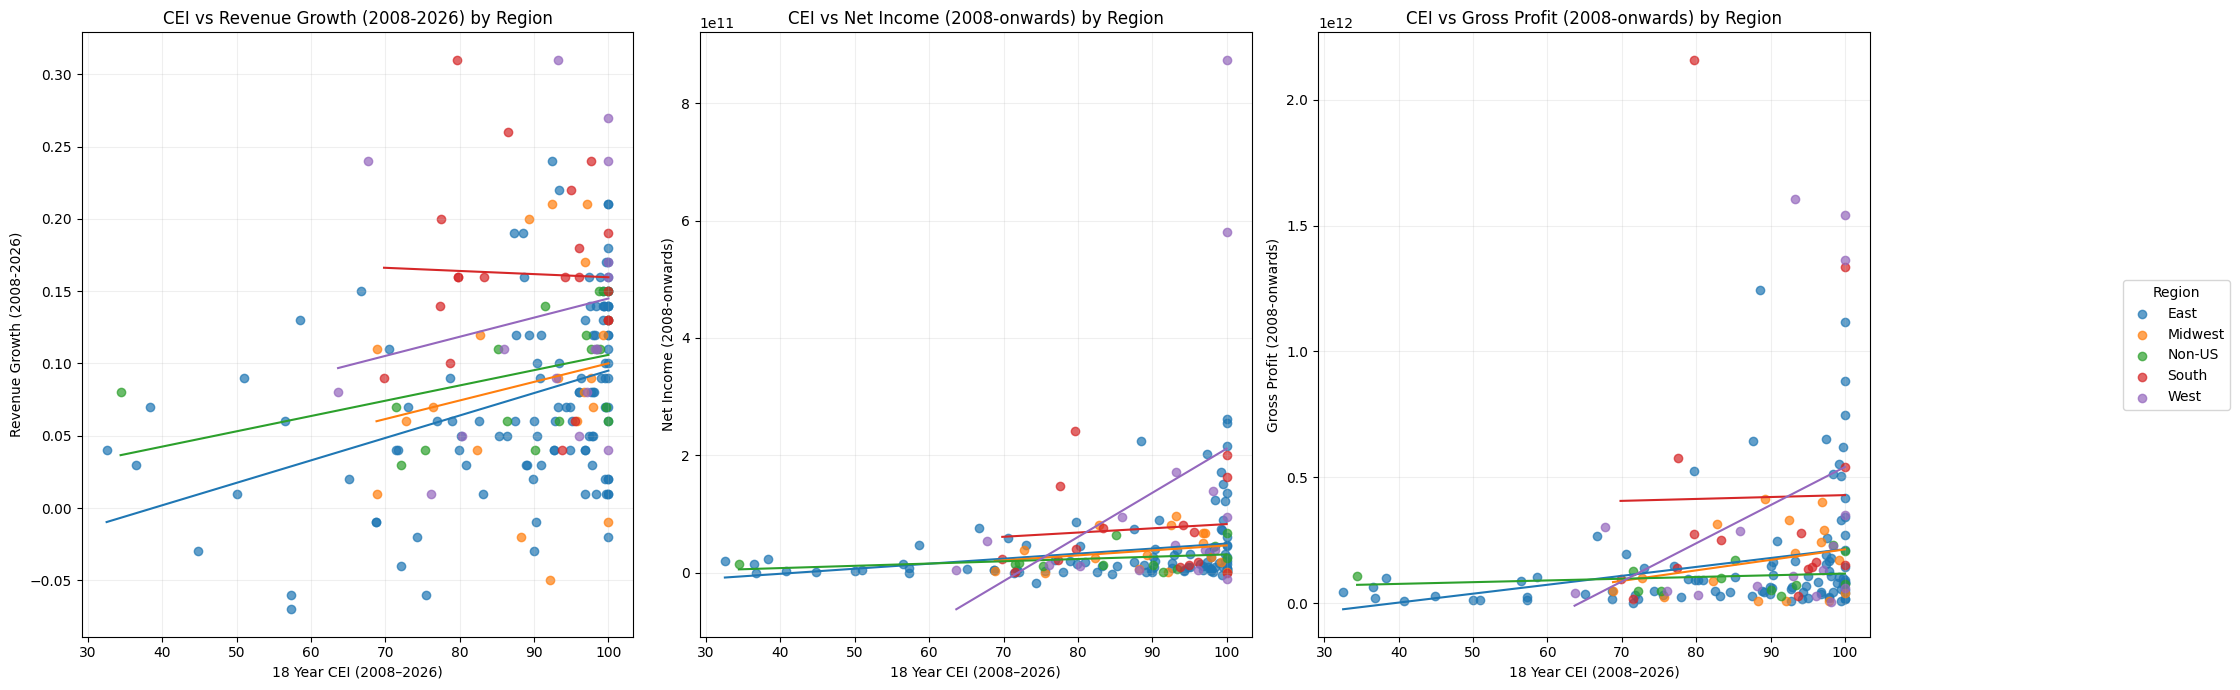

In [62]:
df = pd.read_csv("Stock price_2005_2025_R1(Output).csv")

# First column holds the row labels
labels = df.iloc[:, 0].astype(str)

# Group row = "region"
regions = df[labels == "Region"].iloc[0, 1:]

# Independent (X) and dependent (Y) variables
x = df[labels == "18 Year CEI (2008-2026)"].iloc[0, 1:]
# Dependent variables
y_labels = [
    "Revenue Growth (2008-2026)",
    "Net Income (2008-onwards)",
    "Gross Profit (2008-onwards)"
]

# Create one subplot per dependent variable
fig, axes = plt.subplots(
    nrows=1,
    ncols=len(y_labels),
    figsize=(21, 7),
    sharex=True
)

for ax, y_label in zip(axes, y_labels):

    # Extract dependent variable row
    y = df[labels == y_label].iloc[0, 1:]

    # Build tidy dataframe
    tidy = pd.DataFrame({
        "Region": regions.values,
        "X": pd.to_numeric(x, errors="coerce").values,
        "Y": pd.to_numeric(y, errors="coerce").values
    }).dropna()

    # Remove placeholder values
    tidy = tidy[
        (~tidy["X"].isin([0, -1])) &
        (~tidy["Y"].isin([0, -1]))
    ]

    # Plot each region
    for region, grp in tidy.groupby("Region"):
        ax.scatter(
            grp["X"],
            grp["Y"],
            label=region,
            alpha=0.7
        )

        # Add trendline when the region has at least two valid companies
        if len(grp) > 1 and grp["X"].nunique() > 1:
            coef = np.polyfit(grp["X"], grp["Y"], 1)

            xp = np.linspace(
                grp["X"].min(),
                grp["X"].max(),
                100
            )

            ax.plot(
                xp,
                np.polyval(coef, xp)
            )

    ax.set_xlabel("18 Year CEI (2008–2026)")
    ax.set_ylabel(y_label)
    ax.set_title(f"CEI vs {y_label} by Region")
    ax.grid(alpha=0.2)

# Use one shared legend instead of repeating it on each subplot
handles, legend_labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    legend_labels,
    title="Region",
    bbox_to_anchor=(1.01, 0.5),
    loc="center left"
)

plt.tight_layout(rect=[0, 0, 0.9, 1])
plt.show()


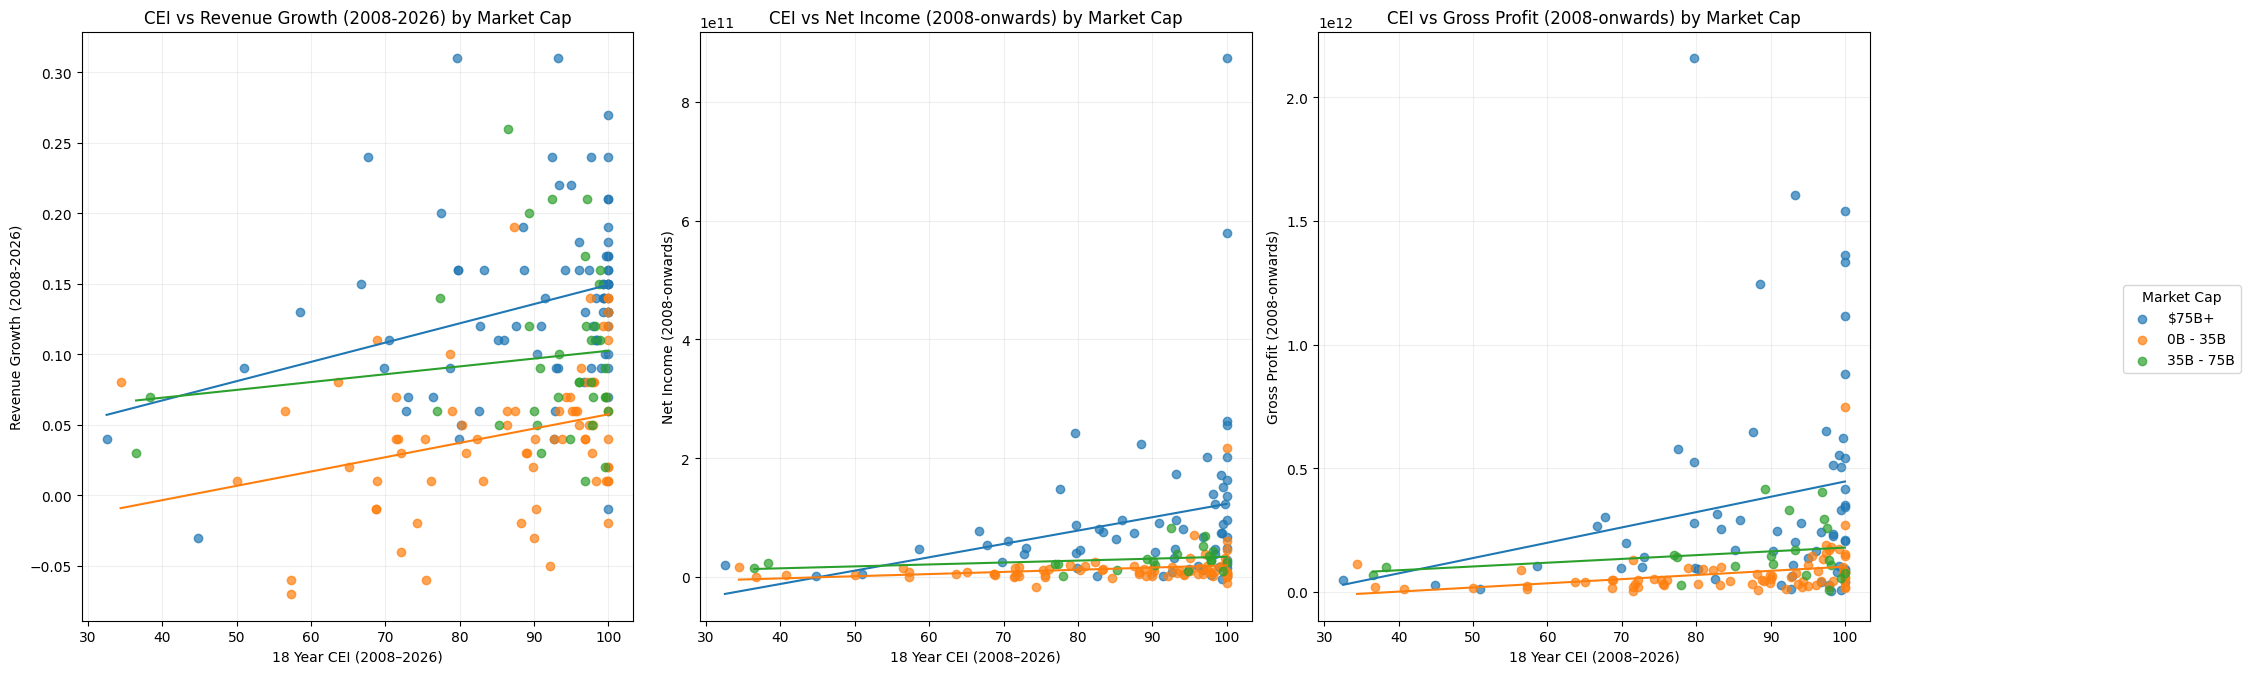

In [63]:
df = pd.read_csv("Stock price_2005_2025_R1(Output).csv")

# Row labels
labels = df.iloc[:, 0].astype(str)

# Group row
mcap = df[labels == "Market Cap (USD Billions)"].iloc[0, 1:]

# Independent variable
x_label = "18 Year CEI (2008-2026)"
x = df[labels == x_label].iloc[0, 1:]

# Dependent variables
y_labels = [
    "Revenue Growth (2008-2026)",
    "Net Income (2008-onwards)",
    "Gross Profit (2008-onwards)"
]

# Create one subplot per dependent variable
fig, axes = plt.subplots(
    nrows=1,
    ncols=len(y_labels),
    figsize=(21, 7),
    sharex=True
)

for ax, y_label in zip(axes, y_labels):

    # Extract dependent variable
    y = df[labels == y_label].iloc[0, 1:]

    # Build tidy company-level dataset
    tidy = pd.DataFrame({
        "Market Cap": mcap.values,
        "X": pd.to_numeric(x, errors="coerce").values,
        "Y": pd.to_numeric(y, errors="coerce").values
    }).dropna()

    # Remove placeholder values
    tidy = tidy[
        (~tidy["X"].isin([0, -1])) &
        (~tidy["Y"].isin([0, -1]))
    ]

    # Plot grouped by Market Cap
    for g, grp in tidy.groupby("Market Cap"):
        ax.scatter(
            grp["X"],
            grp["Y"],
            label=g,
            alpha=0.7
        )

        # Fit trendline only when possible
        if len(grp) > 1 and grp["X"].nunique() > 1:
            coef = np.polyfit(grp["X"], grp["Y"], 1)

            xp = np.linspace(
                grp["X"].min(),
                grp["X"].max(),
                100
            )

            ax.plot(
                xp,
                np.polyval(coef, xp)
            )

    ax.set_xlabel("18 Year CEI (2008–2026)")
    ax.set_ylabel(y_label)
    ax.set_title(f"CEI vs {y_label} by Market Cap")
    ax.grid(alpha=0.2)

# Create one shared legend
handles, legend_labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    legend_labels,
    title="Market Cap",
    bbox_to_anchor=(1.01, 0.5),
    loc="center left"
)

plt.tight_layout(rect=[0, 0, 0.9, 1])
plt.show()



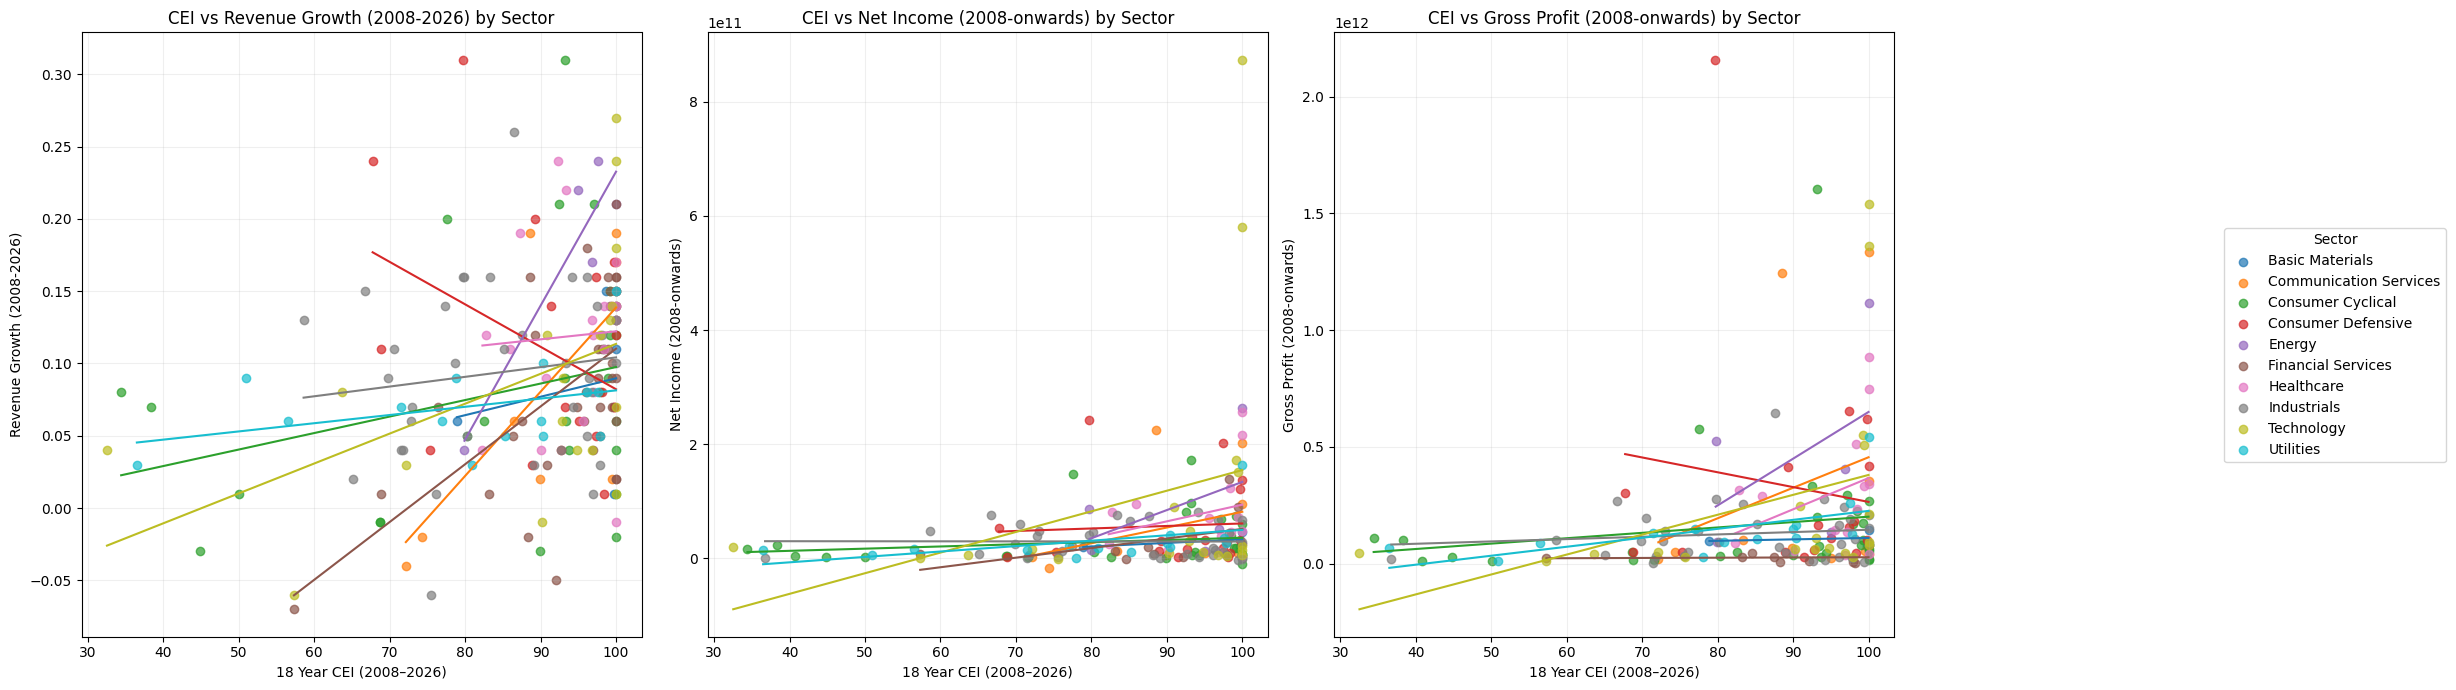

In [64]:
df = pd.read_csv("Stock price_2005_2025_R1(Output).csv")

# First column has the row names
labels = df.iloc[:, 0].astype(str)

# Group row
sectors = df[labels == "Sector"].iloc[0, 1:]

# Independent variable
x_label = "18 Year CEI (2008-2026)"
x = df[labels == x_label].iloc[0, 1:]

# Dependent variables
y_labels = [
    "Revenue Growth (2008-2026)",
    "Net Income (2008-onwards)",
    "Gross Profit (2008-onwards)"
]

# Create one subplot for each dependent variable
fig, axes = plt.subplots(
    nrows=1,
    ncols=len(y_labels),
    figsize=(22, 7),
    sharex=True
)

for ax, y_label in zip(axes, y_labels):

    # Extract dependent variable row
    y = df[labels == y_label].iloc[0, 1:]

    # Build tidy company-level dataset
    tidy = pd.DataFrame({
        "Sector": sectors.values,
        "X": pd.to_numeric(x, errors="coerce").values,
        "Y": pd.to_numeric(y, errors="coerce").values
    }).dropna()

    # Remove placeholder values
    tidy = tidy[
        (~tidy["X"].isin([0, -1])) &
        (~tidy["Y"].isin([0, -1]))
    ]

    # Plot grouped by sector
    for sector, grp in tidy.groupby("Sector"):
        ax.scatter(
            grp["X"],
            grp["Y"],
            label=sector,
            alpha=0.7
        )

        # Fit trendline only when there are enough distinct X values
        if len(grp) > 1 and grp["X"].nunique() > 1:
            coef = np.polyfit(grp["X"], grp["Y"], 1)

            xp = np.linspace(
                grp["X"].min(),
                grp["X"].max(),
                100
            )

            ax.plot(
                xp,
                np.polyval(coef, xp)
            )

    ax.set_xlabel("18 Year CEI (2008–2026)")
    ax.set_ylabel(y_label)
    ax.set_title(f"CEI vs {y_label} by Sector")
    ax.grid(alpha=0.2)

# Create one shared sector legend
handles, legend_labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    legend_labels,
    title="Sector",
    bbox_to_anchor=(1.01, 0.5),
    loc="center left",
    ncol=1
)

plt.tight_layout(rect=[0, 0, 0.87, 1])
plt.show()

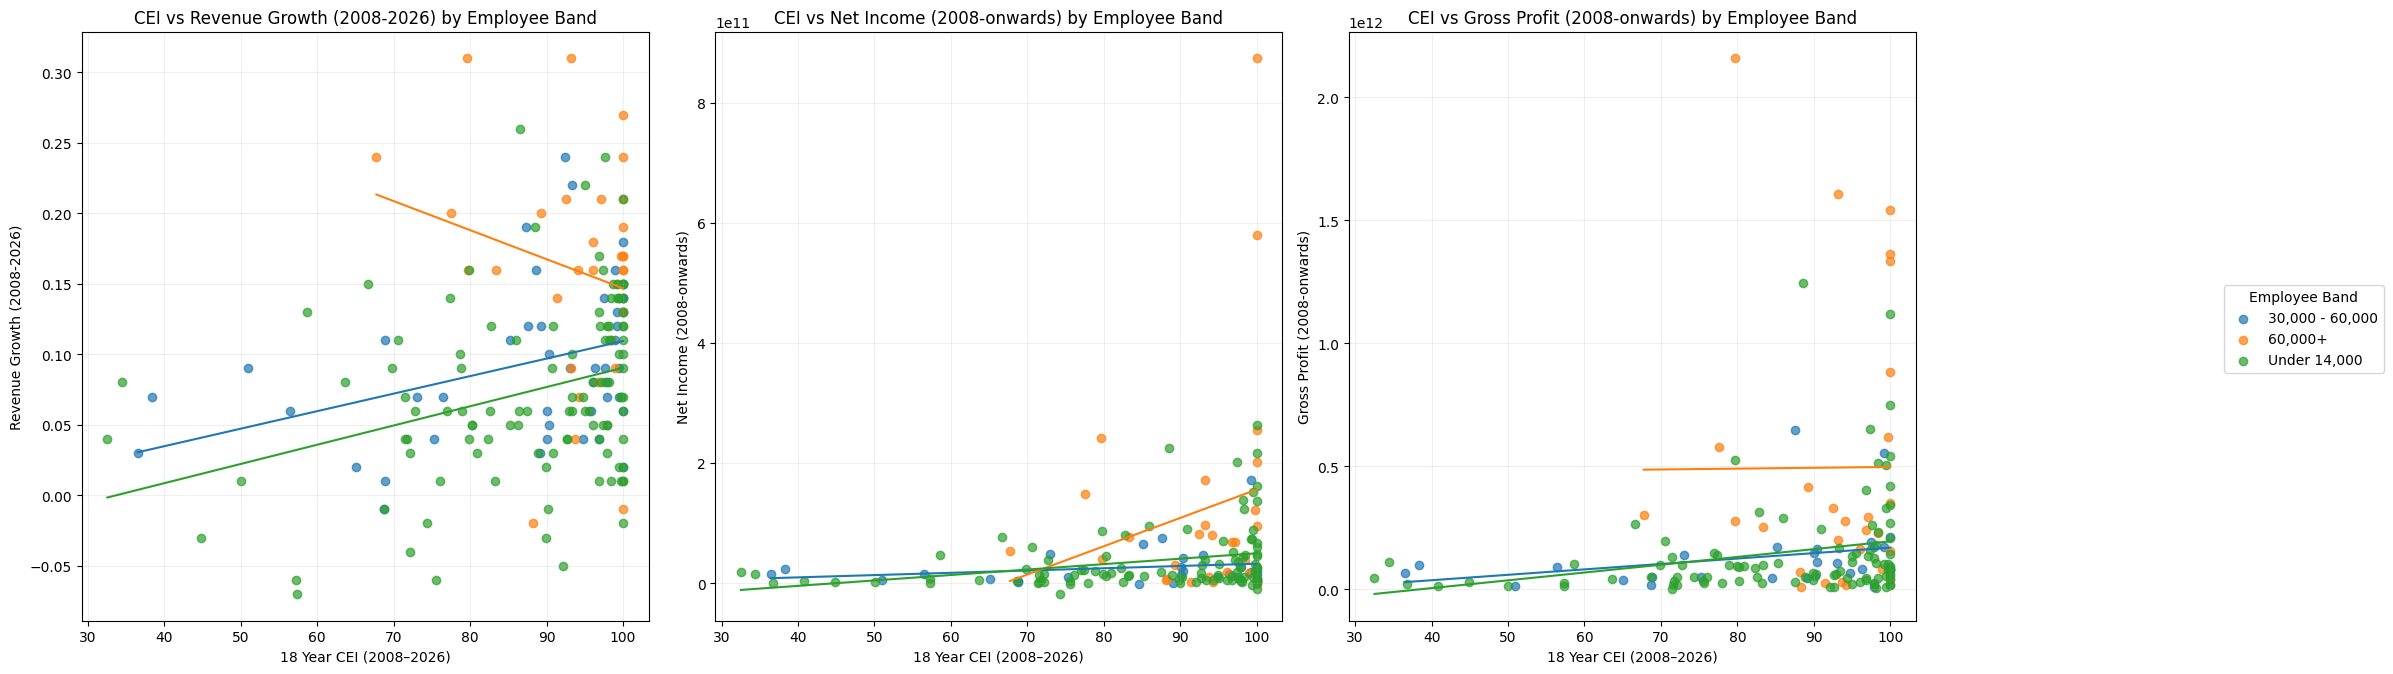

In [65]:
df = pd.read_csv("Stock price_2005_2025_R1(Output).csv")

# First column has the row names
labels = df.iloc[:, 0].astype(str)

# Group row
emp_band = df[labels == "Employee Headcount"].iloc[0, 1:]

# Independent variable
x_label = "18 Year CEI (2008-2026)"
x = df[labels == x_label].iloc[0, 1:]

# Dependent variables
y_labels = [
    "Revenue Growth (2008-2026)",
    "Net Income (2008-onwards)",
    "Gross Profit (2008-onwards)"
]

# Create one subplot per dependent variable
fig, axes = plt.subplots(
    nrows=1,
    ncols=len(y_labels),
    figsize=(22, 7),
    sharex=True
)

for ax, y_label in zip(axes, y_labels):

    # Extract dependent variable
    y = df[labels == y_label].iloc[0, 1:]

    # Build tidy dataframe
    tidy = pd.DataFrame({
        "Employee Band": emp_band.values,
        "X": pd.to_numeric(x, errors="coerce").values,
        "Y": pd.to_numeric(y, errors="coerce").values
    }).dropna()

    # Remove placeholder values
    tidy = tidy[
        (~tidy["X"].isin([0, -1])) &
        (~tidy["Y"].isin([0, -1]))
    ]

    # Plot by Employee Band
    for band, grp in tidy.groupby("Employee Band"):
        ax.scatter(
            grp["X"],
            grp["Y"],
            label=band,
            alpha=0.7
        )

        # Fit trendline only when possible
        if len(grp) > 1 and grp["X"].nunique() > 1:
            coef = np.polyfit(grp["X"], grp["Y"], 1)

            xp = np.linspace(
                grp["X"].min(),
                grp["X"].max(),
                100
            )

            ax.plot(
                xp,
                np.polyval(coef, xp)
            )

    ax.set_xlabel("18 Year CEI (2008–2026)")
    ax.set_ylabel(y_label)
    ax.set_title(f"CEI vs {y_label} by Employee Band")
    ax.grid(alpha=0.2)

# Create one shared legend
handles, legend_labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    legend_labels,
    title="Employee Band",
    bbox_to_anchor=(1.01, 0.5),
    loc="center left"
)

plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.show()



In [66]:
df = pd.read_csv("Stock price_2005_2025_R1(Output).csv")

# First column contains the row labels
labels = df.iloc[:, 0].astype(str).str.strip()

# Category row names
category_rows = {
    "Employee Headcount": "Employee Headcount",
    "Sector": "Sector",
    "Market Cap": "Market Cap (USD Billions)",
    "Region": "Region"
}

# Each column after the first represents one ticker/company
ticker_columns = df.columns[1:]

# Build a company-level dataframe
company_data = pd.DataFrame({
    "Ticker": ticker_columns
})

for category_name, row_label in category_rows.items():
    matching_rows = df[labels == row_label]

    if matching_rows.empty:
        raise ValueError(f'Row "{row_label}" was not found in the CSV.')

    company_data[category_name] = (
        matching_rows.iloc[0, 1:]
        .astype(str)
        .str.strip()
        .values
    )

# Replace invalid category values with missing values
invalid_values = ["", "nan", "NaN", "None", "0", "-1"]

for category_name in category_rows:
    company_data[category_name] = company_data[category_name].replace(
        invalid_values,
        pd.NA
    )

print("Company-level data:")
print(company_data.head())

Company-level data:
  Ticker Employee Headcount       Sector Market Cap   Region
0      A       Under 14,000  Industrials   0B - 35B     West
1    AAA               <NA>         <NA>       <NA>     <NA>
2    AAL            60,000+  Industrials   0B - 35B    South
3   AAPL            60,000+   Technology      $75B+     West
4    ABT       Under 14,000   Healthcare      $75B+  Midwest


In [67]:
individual_counts = {}

for category_name in category_rows:
    counts = (
        company_data
        .dropna(subset=[category_name])
        .groupby(category_name)["Ticker"]
        .nunique()
        .reset_index(name="Ticker Count")
        .sort_values("Ticker Count", ascending=False)
        .reset_index(drop=True)
    )

    individual_counts[category_name] = counts

    print(f"\n{'=' * 60}")
    print(f"TICKER COUNTS BY {category_name.upper()}")
    print(f"{'=' * 60}")
    print(counts.to_string(index=False))


TICKER COUNTS BY EMPLOYEE HEADCOUNT
Employee Headcount  Ticker Count
      Under 14,000           123
   30,000 - 60,000            50
           60,000+            33

TICKER COUNTS BY SECTOR
                Sector  Ticker Count
    Financial Services            43
           Industrials            39
     Consumer Cyclical            30
            Healthcare            20
            Technology            19
    Consumer Defensive            18
             Utilities            16
Communication Services            11
                Energy             6
       Basic Materials             4

TICKER COUNTS BY MARKET CAP
Market Cap  Ticker Count
     $75B+            86
  0B - 35B            84
 35B - 75B            36

TICKER COUNTS BY REGION
 Region  Ticker Count
   East           127
 Non-US            21
  South            21
Midwest            20
   West            17


In [68]:
from itertools import combinations
pair_counts = {}

category_names = list(category_rows.keys())

for category_1, category_2 in combinations(category_names, 2):
    counts = (
        company_data
        .dropna(subset=[category_1, category_2])
        .groupby([category_1, category_2])["Ticker"]
        .nunique()
        .reset_index(name="Ticker Count")
        .sort_values(
            ["Ticker Count", category_1, category_2],
            ascending=[False, True, True]
        )
        .reset_index(drop=True)
    )

    pair_name = f"{category_1} + {category_2}"
    pair_counts[pair_name] = counts

    print(f"\n{'=' * 80}")
    print(f"TICKER COUNTS BY {pair_name.upper()}")
    print(f"{'=' * 80}")
    print(counts.to_string(index=False))


TICKER COUNTS BY EMPLOYEE HEADCOUNT + SECTOR
Employee Headcount                 Sector  Ticker Count
      Under 14,000            Industrials            24
   30,000 - 60,000     Financial Services            22
      Under 14,000      Consumer Cyclical            17
      Under 14,000     Financial Services            15
      Under 14,000             Healthcare            14
      Under 14,000             Technology            13
      Under 14,000     Consumer Defensive            11
      Under 14,000              Utilities            10
      Under 14,000 Communication Services             9
           60,000+      Consumer Cyclical             8
           60,000+            Industrials             8
   30,000 - 60,000            Industrials             7
   30,000 - 60,000              Utilities             6
           60,000+     Financial Services             6
      Under 14,000                 Energy             6
   30,000 - 60,000      Consumer Cyclical             5
  

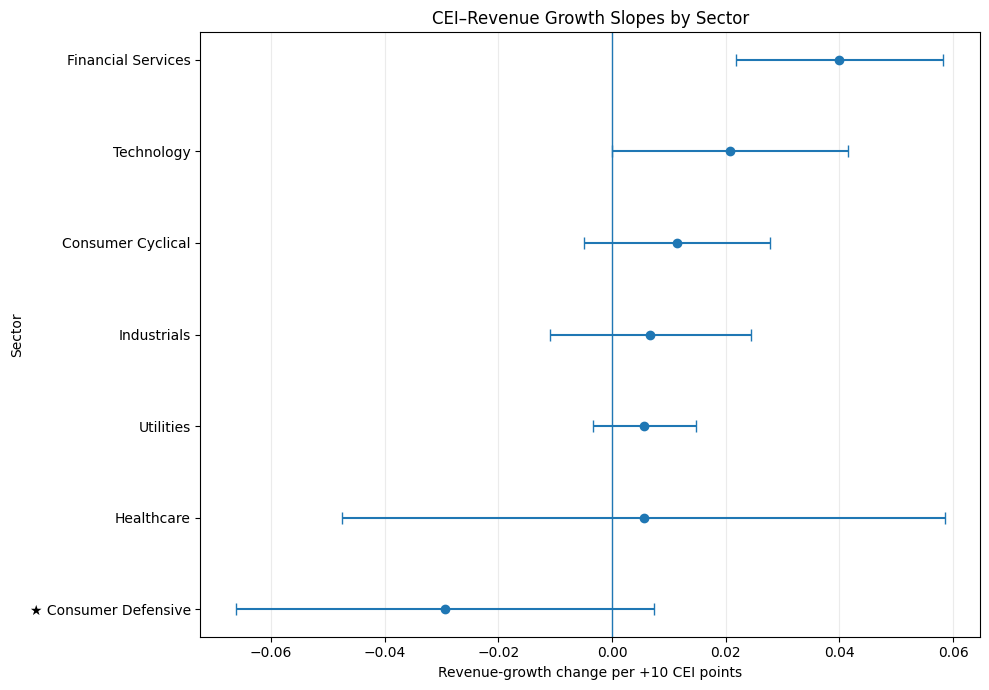

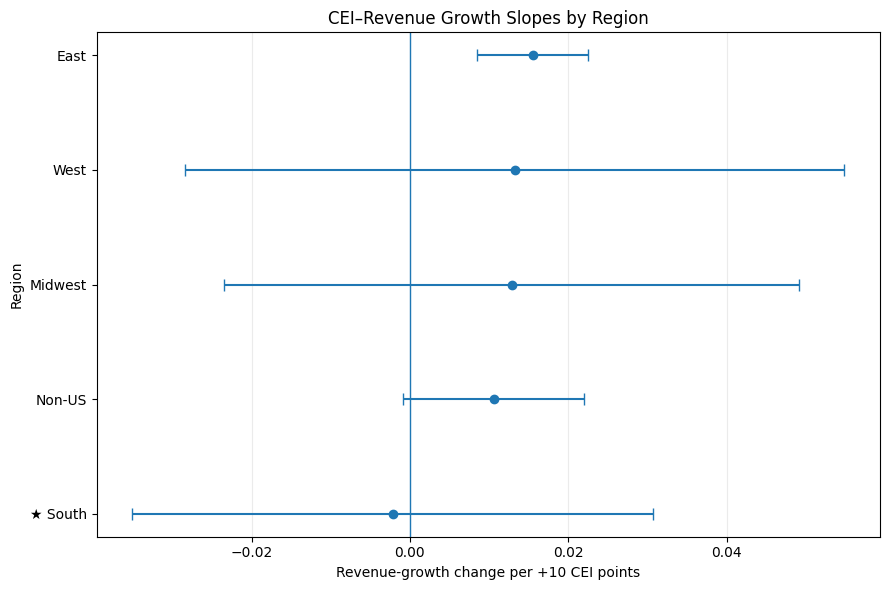

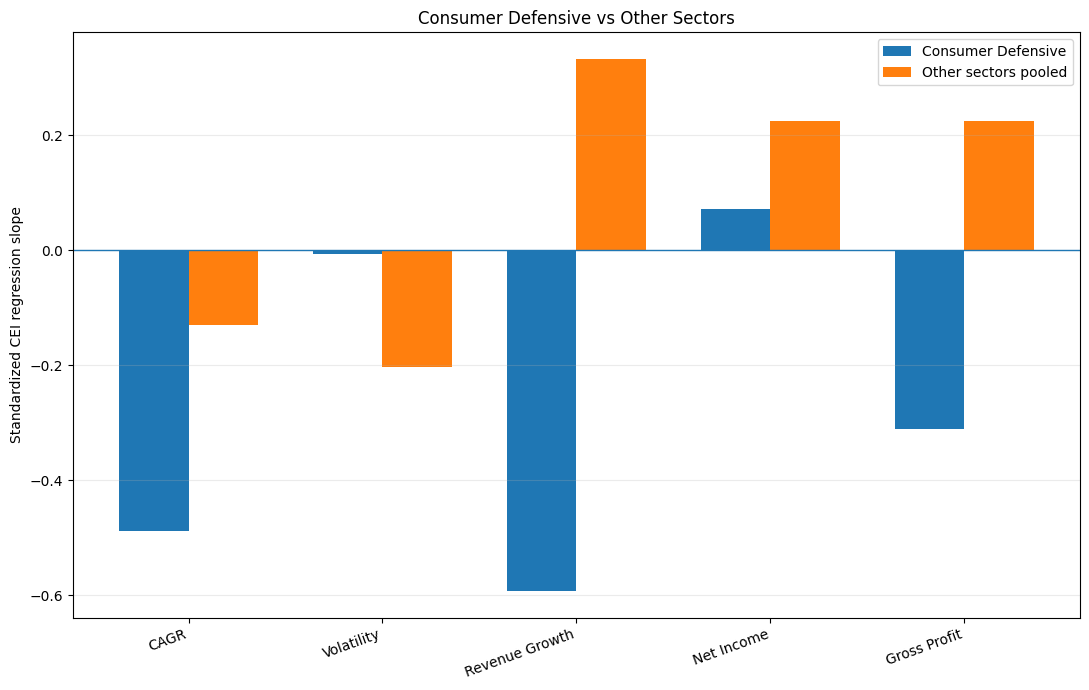

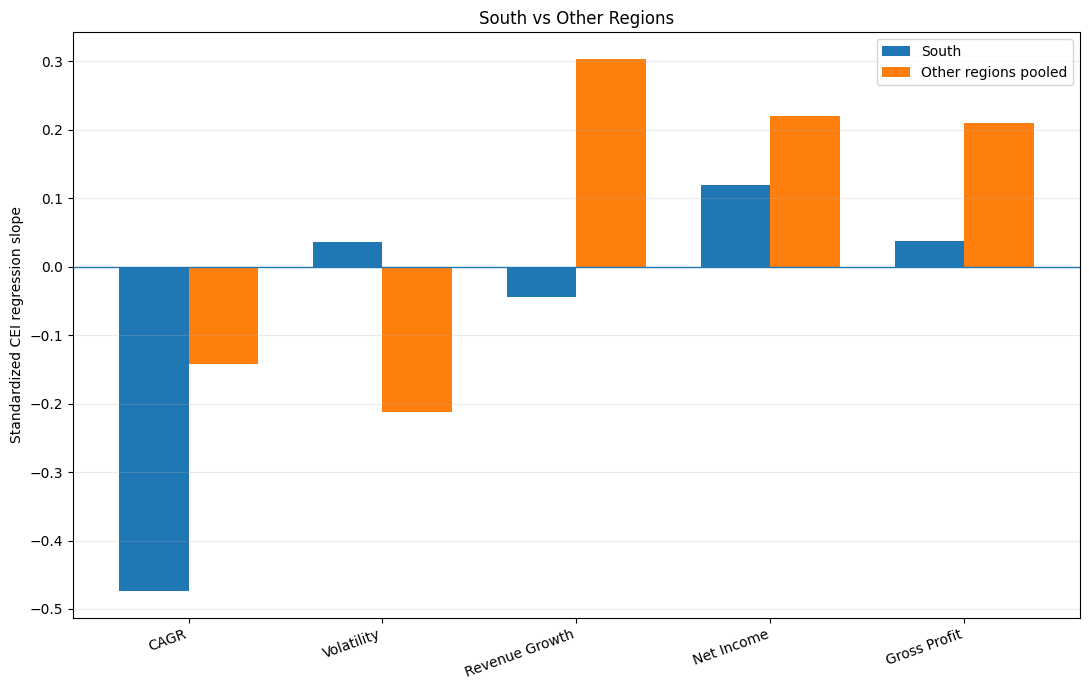

In [69]:
df = pd.read_csv("Stock price_2005_2025_R1(Output).csv")
labels = df.iloc[:, 0].astype(str)
tickers = df.columns[1:]

def get_row(label):
    matches = df.loc[labels.eq(label)]
    if len(matches) != 1:
        raise ValueError(f'Expected exactly one row named "{label}", found {len(matches)}.')
    series = matches.iloc[0, 1:].copy()
    series.index = tickers
    return series

company = pd.DataFrame(index=tickers)
company["Sector"] = get_row("Sector")
company["Region"] = get_row("Region")
company["Employee Headcount"] = get_row("Employee Headcount")
company["Market Cap"] = get_row("Market Cap (USD Billions)")
company["CEI"] = pd.to_numeric(get_row("18 Year CEI (2008-2026)"), errors="coerce")

outcomes = {
    "CAGR": "18 Year CAGR (2008-2026)",
    "Volatility": "18 Year Vol (2008-2026)",
    "Revenue Growth": "Revenue Growth (2008-2026)",
    "Net Income": "Net Income (2008-onwards)",
    "Gross Profit": "Gross Profit (2008-onwards)",
}

for short_name, row_name in outcomes.items():
    company[short_name] = pd.to_numeric(get_row(row_name), errors="coerce")

company.index.name = "Ticker"
company = company.reset_index()

def clean_data(outcome, category=None):
    columns = ["Ticker", "CEI", outcome]
    if category:
        columns.append(category)

    cleaned = company[columns].dropna().copy()


    cleaned = cleaned[
        ~cleaned["CEI"].isin([0, -1])
        & ~cleaned[outcome].isin([0, -1])
    ]
    return cleaned

def simple_regression(data, outcome):
    if len(data) < 2 or data["CEI"].nunique() < 2:
        return None

    model = sm.OLS(data[outcome], sm.add_constant(data["CEI"])).fit()
    ci = model.conf_int().loc["CEI"]

    return {
        "N": len(data),
        "Slope per +10 CEI": 10 * model.params["CEI"],
        "CI low": 10 * ci.iloc[0],
        "CI high": 10 * ci.iloc[1],
        "R2": model.rsquared,
        "Slope p-value": model.pvalues["CEI"],
        "Mean outcome": data[outcome].mean(),
        "Mean CEI": data["CEI"].mean(),
        "Standardized beta": data["CEI"].corr(data[outcome]),
    }

def subgroup_regressions(category, minimum_n=4):
    records = []

    for outcome in outcomes:
        data = clean_data(outcome, category)

        for group, group_data in data.groupby(category):
            if len(group_data) < minimum_n:
                continue

            result = simple_regression(group_data, outcome)
            if result:
                records.append({
                    "Category": category,
                    "Group": group,
                    "Outcome": outcome,
                    **result,
                })

    return pd.DataFrame(records)

def target_vs_others(category, target):
    records = []

    for outcome in outcomes:
        data = clean_data(outcome, category)
        data["Target"] = (data[category] == target).astype(int)

        target_data = data[data["Target"] == 1]
        other_data = data[data["Target"] == 0]

        target_result = simple_regression(target_data, outcome)
        other_result = simple_regression(other_data, outcome)

        if not target_result or not other_result:
            continue

        median_cei = data["CEI"].median()
        data["CEI centered"] = data["CEI"] - median_cei

        design = pd.DataFrame({
            "const": 1.0,
            "CEI centered": data["CEI centered"],
            "Target": data["Target"],
            "Interaction": data["CEI centered"] * data["Target"],
        })

        interaction_model = sm.OLS(data[outcome], design).fit()

        target_mean = target_data[outcome].mean()
        other_mean = other_data[outcome].mean()

        mean_test = stats.ttest_ind(
            target_data[outcome],
            other_data[outcome],
            equal_var=False,
            nan_policy="omit",
        )

        pooled_x_sd = data["CEI"].std(ddof=1)
        pooled_y_sd = data[outcome].std(ddof=1)

        records.append({
            "Outcome": outcome,
            "Target": target,
            "Target N": len(target_data),
            "Others N": len(other_data),
            "Target mean": target_mean,
            "Others mean": other_mean,
            "Raw mean difference": target_mean - other_mean,
            "Raw mean difference p-value": mean_test.pvalue,
            "Comparison CEI": median_cei,
            "Adjusted difference at median CEI": interaction_model.params["Target"],
            "Adjusted difference p-value": interaction_model.pvalues["Target"],
            "Target slope per +10 CEI": target_result["Slope per +10 CEI"],
            "Others slope per +10 CEI": other_result["Slope per +10 CEI"],
            "Slope difference per +10 CEI": 10 * interaction_model.params["Interaction"],
            "Slope difference p-value": interaction_model.pvalues["Interaction"],
            "Target R2": target_result["R2"],
            "Others R2": other_result["R2"],
            "Target slope p-value": target_result["Slope p-value"],
            "Others slope p-value": other_result["Slope p-value"],
            "Target standardized beta":
                (target_result["Slope per +10 CEI"] / 10) * pooled_x_sd / pooled_y_sd,
            "Others standardized beta":
                (other_result["Slope per +10 CEI"] / 10) * pooled_x_sd / pooled_y_sd,
        })

    return pd.DataFrame(records)

def pairwise_target_comparisons(category, target, minimum_n=10):
    records = []
    peers = [value for value in company[category].dropna().unique() if value != target]

    for outcome in outcomes:
        full_data = clean_data(outcome, category)

        for peer in peers:
            data = full_data[full_data[category].isin([target, peer])].copy()
            counts = data[category].value_counts()

            if (
                target not in counts
                or peer not in counts
                or counts[target] < minimum_n
                or counts[peer] < minimum_n
            ):
                continue

            data["Target"] = (data[category] == target).astype(int)
            design = pd.DataFrame({
                "const": 1.0,
                "CEI": data["CEI"],
                "Target": data["Target"],
                "Interaction": data["CEI"] * data["Target"],
            })

            model = sm.OLS(data[outcome], design).fit()
            target_result = simple_regression(data[data["Target"] == 1], outcome)
            peer_result = simple_regression(data[data["Target"] == 0], outcome)

            records.append({
                "Outcome": outcome,
                "Target": target,
                "Peer": peer,
                "Target N": target_result["N"],
                "Peer N": peer_result["N"],
                "Target slope per +10 CEI": target_result["Slope per +10 CEI"],
                "Peer slope per +10 CEI": peer_result["Slope per +10 CEI"],
                "Slope difference per +10 CEI": 10 * model.params["Interaction"],
                "Interaction p-value": model.pvalues["Interaction"],
                "Target R2": target_result["R2"],
                "Peer R2": peer_result["R2"],
            })

    results = pd.DataFrame(records)

    if not results.empty:
        results["FDR-adjusted q-value"] = np.nan
        for outcome, index in results.groupby("Outcome").groups.items():
            results.loc[index, "FDR-adjusted q-value"] = multipletests(
                results.loc[index, "Interaction p-value"],
                method="fdr_bh",
            )[1]

    return results

sector_results = subgroup_regressions("Sector")
region_results = subgroup_regressions("Region")

consumer_summary = target_vs_others("Sector", "Consumer Defensive")
south_summary = target_vs_others("Region", "South")

consumer_pairwise = pairwise_target_comparisons(
    "Sector", "Consumer Defensive", minimum_n=10
)
south_pairwise = pairwise_target_comparisons(
    "Region", "South", minimum_n=10
)

#display(sector_results)
#display(region_results)
#display(consumer_summary)
#display(south_summary)
#display(consumer_pairwise)
#display(south_pairwise)

# rev
sector_chart = (
    sector_results[
        (sector_results["Outcome"] == "Revenue Growth")
        & (sector_results["N"] >= 10)
    ]
    .sort_values("Slope per +10 CEI")
    .copy()
)

sector_chart["Display group"] = sector_chart["Group"].where(
    sector_chart["Group"] != "Consumer Defensive",
    "★ Consumer Defensive",
)

lower_error = sector_chart["Slope per +10 CEI"] - sector_chart["CI low"]
upper_error = sector_chart["CI high"] - sector_chart["Slope per +10 CEI"]

fig, ax = plt.subplots(figsize=(10, 7))
ax.errorbar(
    sector_chart["Slope per +10 CEI"],
    sector_chart["Display group"],
    xerr=np.vstack([lower_error, upper_error]),
    fmt="o",
    capsize=4,
)
ax.axvline(0, linewidth=1)
ax.set_xlabel("Revenue-growth change per +10 CEI points")
ax.set_ylabel("Sector")
ax.set_title("CEI–Revenue Growth Slopes by Sector")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
sector_path = output_dir / "revenue_growth_slopes_by_sector.png"
#fig.savefig(sector_path, dpi=200, bbox_inches="tight")
plt.show()

# rev
region_chart = (
    region_results[
        (region_results["Outcome"] == "Revenue Growth")
        & (region_results["N"] >= 10)
    ]
    .sort_values("Slope per +10 CEI")
    .copy()
)

region_chart["Display group"] = region_chart["Group"].where(
    region_chart["Group"] != "South",
    "★ South",
)

lower_error = region_chart["Slope per +10 CEI"] - region_chart["CI low"]
upper_error = region_chart["CI high"] - region_chart["Slope per +10 CEI"]

fig, ax = plt.subplots(figsize=(9, 6))
ax.errorbar(
    region_chart["Slope per +10 CEI"],
    region_chart["Display group"],
    xerr=np.vstack([lower_error, upper_error]),
    fmt="o",
    capsize=4,
)
ax.axvline(0, linewidth=1)
ax.set_xlabel("Revenue-growth change per +10 CEI points")
ax.set_ylabel("Region")
ax.set_title("CEI–Revenue Growth Slopes by Region")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

# Consumer focus
x = np.arange(len(consumer_summary))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 7))
ax.bar(
    x - width / 2,
    consumer_summary["Target standardized beta"],
    width,
    label="Consumer Defensive",
)
ax.bar(
    x + width / 2,
    consumer_summary["Others standardized beta"],
    width,
    label="Other sectors pooled",
)
ax.axhline(0, linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(consumer_summary["Outcome"], rotation=20, ha="right")
ax.set_ylabel("Standardized CEI regression slope")
ax.set_title("Consumer Defensive vs Other Sectors")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

# South focus
x = np.arange(len(south_summary))

fig, ax = plt.subplots(figsize=(11, 7))
ax.bar(
    x - width / 2,
    south_summary["Target standardized beta"],
    width,
    label="South",
)
ax.bar(
    x + width / 2,
    south_summary["Others standardized beta"],
    width,
    label="Other regions pooled",
)
ax.axhline(0, linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(south_summary["Outcome"], rotation=20, ha="right")
ax.set_ylabel("Standardized CEI regression slope")
ax.set_title("South vs Other Regions")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()



Outlier removal: ON

Influential observations identified:


,Ticker,Outcome,Category,Group,CEI,Outcome value,Cooks D,Cook cutoff
0,TXN,CAGR,Region,South,95.57,2.100000e-01,0.223003,0.222222
1,COST,CAGR,Sector,Consumer Defensive,67.74,2.000000e-01,1.480083,0.250000
2,TAP,CAGR,Sector,Consumer Defensive,75.28,1.000000e-02,0.901478,0.250000
3,WMT,Gross Profit,Region,South,79.65,2.158078e+12,0.542572,0.266667
4,WMT,Gross Profit,Sector,Consumer Defensive,79.65,2.158078e+12,0.862355,0.235294
5,WMT,Net Income,Region,South,79.65,2.420980e+11,0.300926,0.266667
6,WMT,Net Income,Sector,Consumer Defensive,79.65,2.420980e+11,0.480165,0.235294
7,WM,Revenue Growth,Region,South,69.83,9.000000e-02,0.293255,0.200000
8,WMT,Revenue Growth,Region,South,79.65,3.100000e-01,0.288323,0.200000
9,WMT,Revenue Growth,Sector,Consumer Defensive,79.65,3.100000e-01,0.369661,0.222222


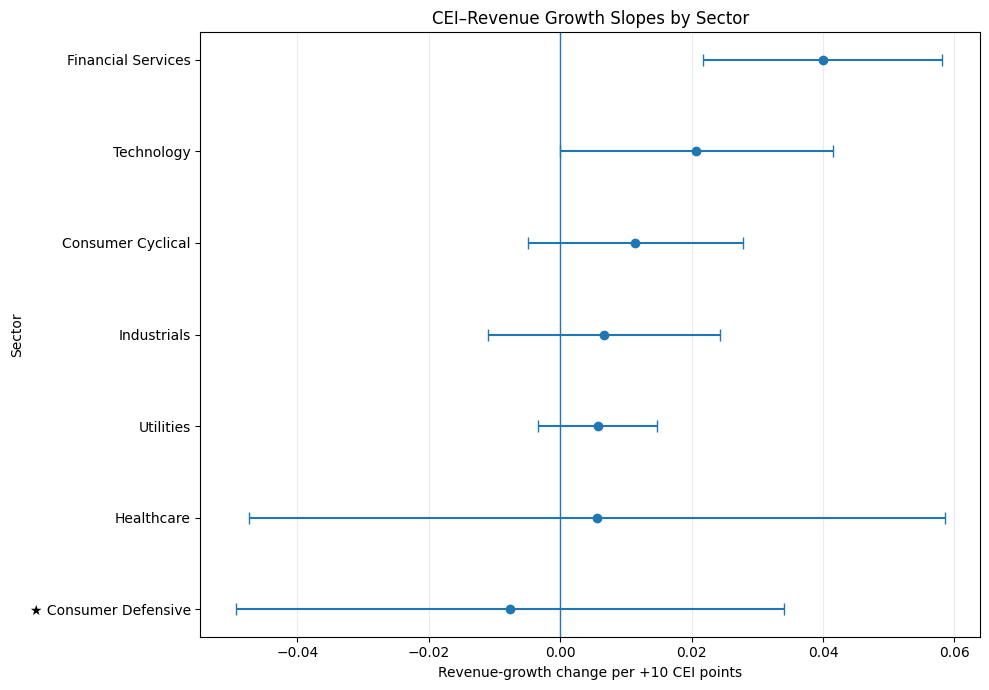

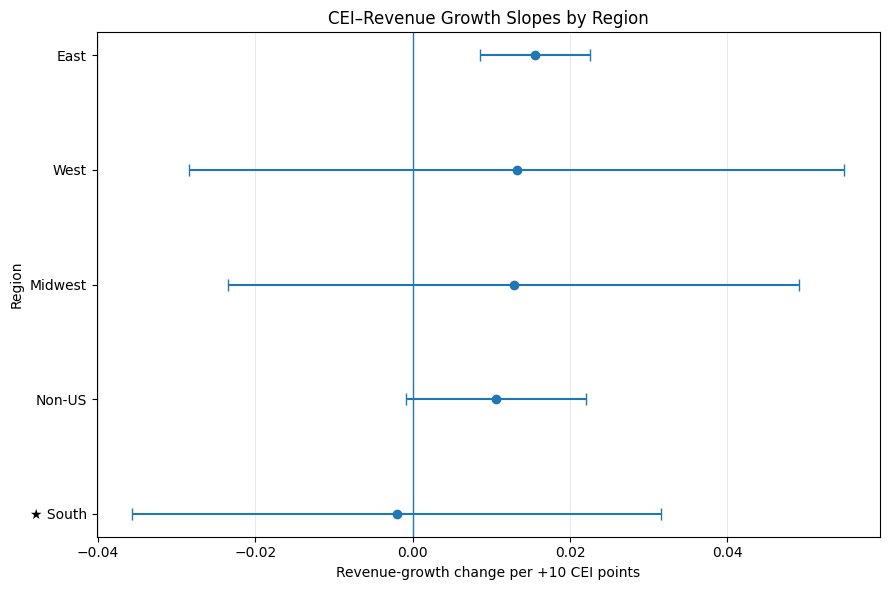

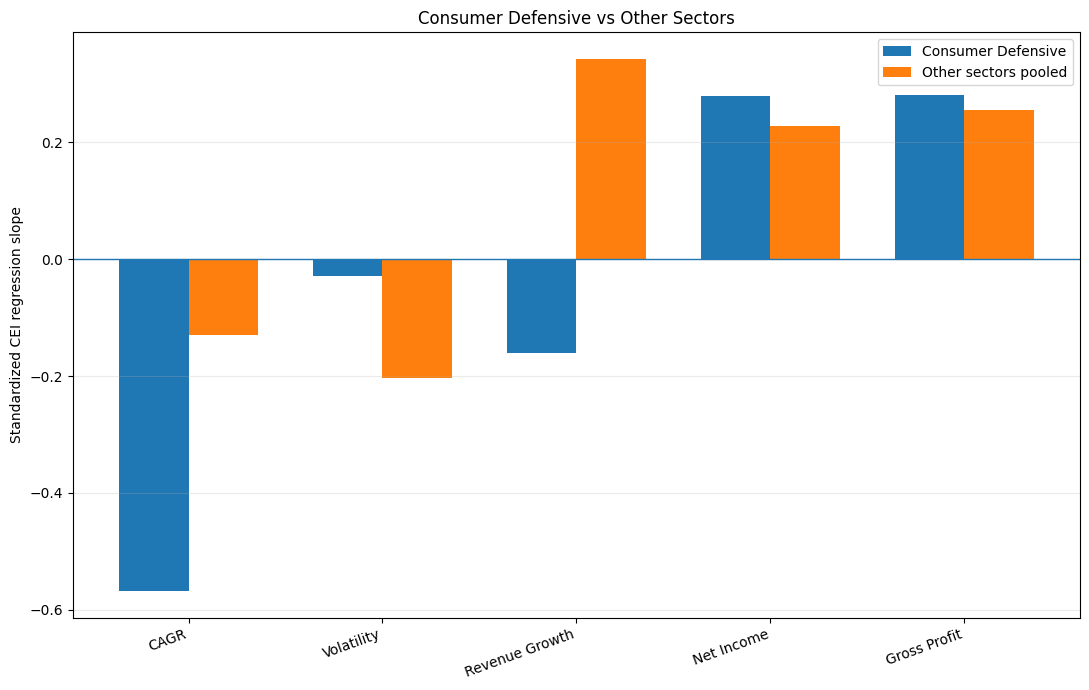

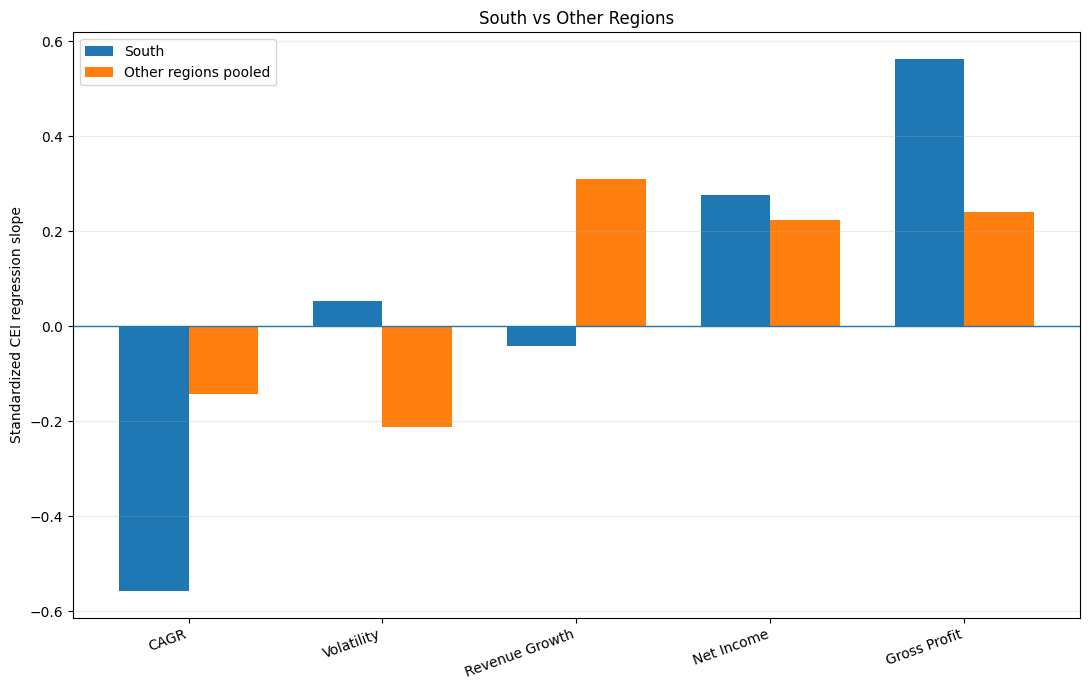

In [70]:

REMOVE_TARGET_OUTLIERS = True

TARGET_GROUPS = {
    "Sector": "Consumer Defensive",
    "Region": "South",
}



df = pd.read_csv("Stock price_2005_2025_R1(Output).csv")

labels = df.iloc[:, 0].astype(str)
tickers = df.columns[1:]


def get_row(label):
    matches = df.loc[labels.eq(label)]

    if len(matches) != 1:
        raise ValueError(
            f'Expected exactly one row named "{label}", '
            f"found {len(matches)}."
        )

    series = matches.iloc[0, 1:].copy()
    series.index = tickers
    return series


company = pd.DataFrame(index=tickers)

company["Sector"] = get_row("Sector")
company["Region"] = get_row("Region")
company["Employee Headcount"] = get_row("Employee Headcount")
company["Market Cap"] = get_row("Market Cap (USD Billions)")
company["CEI"] = pd.to_numeric(
    get_row("18 Year CEI (2008-2026)"),
    errors="coerce",
)

outcomes = {
    "CAGR": "18 Year CAGR (2008-2026)",
    "Volatility": "18 Year Vol (2008-2026)",
    "Revenue Growth": "Revenue Growth (2008-2026)",
    "Net Income": "Net Income (2008-onwards)",
    "Gross Profit": "Gross Profit (2008-onwards)",
}

for short_name, row_name in outcomes.items():
    company[short_name] = pd.to_numeric(
        get_row(row_name),
        errors="coerce",
    )

company.index.name = "Ticker"
company = company.reset_index()


def find_cooks_outliers(data, outcome):
    """
    Identify influential observations using Cook's distance.
    The regression is fitted within one target group at a time.
    """

    if len(data) < 4 or data["CEI"].nunique() < 2:
        return pd.DataFrame()

    X = sm.add_constant(data["CEI"])
    model = sm.OLS(data[outcome], X).fit()

    result = data.copy()
    result["Cooks D"] = model.get_influence().cooks_distance[0]
    result["Cook cutoff"] = 4 / len(result)

    return result[
        result["Cooks D"] > result["Cook cutoff"]
    ].copy()


def clean_data(
    outcome,
    category=None,
    remove_target_outliers=REMOVE_TARGET_OUTLIERS,
):
    columns = ["Ticker", "CEI", outcome]

    if category:
        columns.append(category)

    cleaned = company[columns].dropna().copy()

    # Remove placeholder values
    cleaned = cleaned[
        (~cleaned["CEI"].isin([0, -1]))
        & (~cleaned[outcome].isin([0, -1]))
    ].copy()

    # Remove influential observations only from:
    # Consumer Defensive when category = Sector
    # South when category = Region
    if remove_target_outliers and category in TARGET_GROUPS:
        target = TARGET_GROUPS[category]

        target_data = cleaned[
            cleaned[category] == target
        ].copy()

        outliers = find_cooks_outliers(
            target_data,
            outcome,
        )

        if not outliers.empty:
            cleaned = cleaned.drop(index=outliers.index)

    return cleaned


def create_outlier_report():
    records = []

    for outcome in outcomes:
        for category, target in TARGET_GROUPS.items():

            # Retrieve data before outlier removal
            data = clean_data(
                outcome,
                category,
                remove_target_outliers=False,
            )

            target_data = data[
                data[category] == target
            ].copy()

            outliers = find_cooks_outliers(
                target_data,
                outcome,
            )

            if outliers.empty:
                continue

            outliers["Outcome"] = outcome
            outliers["Category"] = category
            outliers["Group"] = target

            report_columns = [
                "Ticker",
                "Outcome",
                "Category",
                "Group",
                "CEI",
                outcome,
                "Cooks D",
                "Cook cutoff",
            ]

            records.append(
                outliers[report_columns].rename(
                    columns={outcome: "Outcome value"}
                )
            )

    if not records:
        return pd.DataFrame(
            columns=[
                "Ticker",
                "Outcome",
                "Category",
                "Group",
                "CEI",
                "Outcome value",
                "Cooks D",
                "Cook cutoff",
            ]
        )

    return (
        pd.concat(records, ignore_index=True)
        .sort_values(
            ["Outcome", "Category", "Cooks D"],
            ascending=[True, True, False],
        )
        .reset_index(drop=True)
    )



def simple_regression(data, outcome):
    if len(data) < 2 or data["CEI"].nunique() < 2:
        return None

    X = sm.add_constant(data["CEI"])
    model = sm.OLS(data[outcome], X).fit()

    ci = model.conf_int().loc["CEI"]

    return {
        "N": len(data),
        "Slope per +10 CEI": 10 * model.params["CEI"],
        "CI low": 10 * ci.iloc[0],
        "CI high": 10 * ci.iloc[1],
        "R2": model.rsquared,
        "Slope p-value": model.pvalues["CEI"],
        "Mean outcome": data[outcome].mean(),
        "Mean CEI": data["CEI"].mean(),
        "Standardized beta": data["CEI"].corr(data[outcome]),
    }


def subgroup_regressions(category, minimum_n=4):
    records = []

    for outcome in outcomes:
        data = clean_data(outcome, category)

        for group, group_data in data.groupby(category):
            if len(group_data) < minimum_n:
                continue

            result = simple_regression(
                group_data,
                outcome,
            )

            if result:
                records.append({
                    "Category": category,
                    "Group": group,
                    "Outcome": outcome,
                    **result,
                })

    return pd.DataFrame(records)


def target_vs_others(category, target):
    records = []

    for outcome in outcomes:
        data = clean_data(outcome, category)

        data["Target"] = (
            data[category] == target
        ).astype(int)

        target_data = data[data["Target"] == 1].copy()
        other_data = data[data["Target"] == 0].copy()

        target_result = simple_regression(
            target_data,
            outcome,
        )

        other_result = simple_regression(
            other_data,
            outcome,
        )

        if not target_result or not other_result:
            continue

        median_cei = data["CEI"].median()
        data["CEI centered"] = data["CEI"] - median_cei

        design = pd.DataFrame({
            "const": 1.0,
            "CEI centered": data["CEI centered"],
            "Target": data["Target"],
            "Interaction":
                data["CEI centered"] * data["Target"],
        })

        interaction_model = sm.OLS(
            data[outcome],
            design,
        ).fit()

        mean_test = stats.ttest_ind(
            target_data[outcome],
            other_data[outcome],
            equal_var=False,
            nan_policy="omit",
        )

        pooled_x_sd = data["CEI"].std(ddof=1)
        pooled_y_sd = data[outcome].std(ddof=1)

        records.append({
            "Outcome": outcome,
            "Target": target,
            "Target N": len(target_data),
            "Others N": len(other_data),
            "Target mean": target_data[outcome].mean(),
            "Others mean": other_data[outcome].mean(),
            "Raw mean difference":
                target_data[outcome].mean()
                - other_data[outcome].mean(),
            "Raw mean difference p-value": mean_test.pvalue,
            "Comparison CEI": median_cei,
            "Adjusted difference at median CEI":
                interaction_model.params["Target"],
            "Adjusted difference p-value":
                interaction_model.pvalues["Target"],
            "Target slope per +10 CEI":
                target_result["Slope per +10 CEI"],
            "Others slope per +10 CEI":
                other_result["Slope per +10 CEI"],
            "Slope difference per +10 CEI":
                10 * interaction_model.params["Interaction"],
            "Slope difference p-value":
                interaction_model.pvalues["Interaction"],
            "Target R2": target_result["R2"],
            "Others R2": other_result["R2"],
            "Target slope p-value":
                target_result["Slope p-value"],
            "Others slope p-value":
                other_result["Slope p-value"],
            "Target standardized beta":
                (target_result["Slope per +10 CEI"] / 10)
                * pooled_x_sd
                / pooled_y_sd,
            "Others standardized beta":
                (other_result["Slope per +10 CEI"] / 10)
                * pooled_x_sd
                / pooled_y_sd,
        })

    return pd.DataFrame(records)


def pairwise_target_comparisons(
    category,
    target,
    minimum_n=10,
):
    records = []

    peers = [
        value
        for value in company[category].dropna().unique()
        if value != target
    ]

    for outcome in outcomes:
        full_data = clean_data(outcome, category)

        for peer in peers:
            data = full_data[
                full_data[category].isin([target, peer])
            ].copy()

            counts = data[category].value_counts()

            if (
                target not in counts
                or peer not in counts
                or counts[target] < minimum_n
                or counts[peer] < minimum_n
            ):
                continue

            data["Target"] = (
                data[category] == target
            ).astype(int)

            target_data = data[data["Target"] == 1]
            peer_data = data[data["Target"] == 0]

            target_result = simple_regression(
                target_data,
                outcome,
            )

            peer_result = simple_regression(
                peer_data,
                outcome,
            )

            if not target_result or not peer_result:
                continue

            design = pd.DataFrame({
                "const": 1.0,
                "CEI": data["CEI"],
                "Target": data["Target"],
                "Interaction":
                    data["CEI"] * data["Target"],
            })

            model = sm.OLS(
                data[outcome],
                design,
            ).fit()

            records.append({
                "Outcome": outcome,
                "Target": target,
                "Peer": peer,
                "Target N": target_result["N"],
                "Peer N": peer_result["N"],
                "Target slope per +10 CEI":
                    target_result["Slope per +10 CEI"],
                "Peer slope per +10 CEI":
                    peer_result["Slope per +10 CEI"],
                "Slope difference per +10 CEI":
                    10 * model.params["Interaction"],
                "Interaction p-value":
                    model.pvalues["Interaction"],
                "Target R2": target_result["R2"],
                "Peer R2": peer_result["R2"],
            })

    results = pd.DataFrame(records)

    if not results.empty:
        results["FDR-adjusted q-value"] = np.nan

        for outcome, index in results.groupby(
            "Outcome"
        ).groups.items():

            results.loc[
                index,
                "FDR-adjusted q-value",
            ] = multipletests(
                results.loc[index, "Interaction p-value"],
                method="fdr_bh",
            )[1]

    return results


# ============================================================
# RUN ANALYSES
# ============================================================

outlier_report = create_outlier_report()

sector_results = subgroup_regressions("Sector")
region_results = subgroup_regressions("Region")

consumer_summary = target_vs_others(
    "Sector",
    "Consumer Defensive",
)

south_summary = target_vs_others(
    "Region",
    "South",
)

consumer_pairwise = pairwise_target_comparisons(
    "Sector",
    "Consumer Defensive",
    minimum_n=10,
)

south_pairwise = pairwise_target_comparisons(
    "Region",
    "South",
    minimum_n=10,
)


print(
    "Outlier removal:",
    "ON" if REMOVE_TARGET_OUTLIERS else "OFF",
)

print("\nInfluential observations identified:")
display(outlier_report)

# Uncomment any tables you want to view:
# display(sector_results)
# display(region_results)
# display(consumer_summary)
# display(south_summary)
# display(consumer_pairwise)
# display(south_pairwise)


# ============================================================
# CHART 1: REVENUE-GROWTH SLOPES BY SECTOR
# ============================================================

sector_chart = (
    sector_results[
        (sector_results["Outcome"] == "Revenue Growth")
        & (sector_results["N"] >= 10)
    ]
    .sort_values("Slope per +10 CEI")
    .copy()
)

sector_chart["Display group"] = sector_chart["Group"].where(
    sector_chart["Group"] != "Consumer Defensive",
    "★ Consumer Defensive",
)

lower_error = (
    sector_chart["Slope per +10 CEI"]
    - sector_chart["CI low"]
)

upper_error = (
    sector_chart["CI high"]
    - sector_chart["Slope per +10 CEI"]
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.errorbar(
    sector_chart["Slope per +10 CEI"],
    sector_chart["Display group"],
    xerr=np.vstack([lower_error, upper_error]),
    fmt="o",
    capsize=4,
)

ax.axvline(0, linewidth=1)
ax.set_xlabel("Revenue-growth change per +10 CEI points")
ax.set_ylabel("Sector")
ax.set_title("CEI–Revenue Growth Slopes by Sector")
ax.grid(axis="x", alpha=0.25)

fig.tight_layout()
plt.show()


# ============================================================
# CHART 2: REVENUE-GROWTH SLOPES BY REGION
# ============================================================

region_chart = (
    region_results[
        (region_results["Outcome"] == "Revenue Growth")
        & (region_results["N"] >= 10)
    ]
    .sort_values("Slope per +10 CEI")
    .copy()
)

region_chart["Display group"] = region_chart["Group"].where(
    region_chart["Group"] != "South",
    "★ South",
)

lower_error = (
    region_chart["Slope per +10 CEI"]
    - region_chart["CI low"]
)

upper_error = (
    region_chart["CI high"]
    - region_chart["Slope per +10 CEI"]
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.errorbar(
    region_chart["Slope per +10 CEI"],
    region_chart["Display group"],
    xerr=np.vstack([lower_error, upper_error]),
    fmt="o",
    capsize=4,
)

ax.axvline(0, linewidth=1)
ax.set_xlabel("Revenue-growth change per +10 CEI points")
ax.set_ylabel("Region")
ax.set_title("CEI–Revenue Growth Slopes by Region")
ax.grid(axis="x", alpha=0.25)

fig.tight_layout()
plt.show()


# ============================================================
# CHART 3: CONSUMER DEFENSIVE VS OTHER SECTORS
# ============================================================

x_positions = np.arange(len(consumer_summary))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 7))

ax.bar(
    x_positions - width / 2,
    consumer_summary["Target standardized beta"],
    width,
    label="Consumer Defensive",
)

ax.bar(
    x_positions + width / 2,
    consumer_summary["Others standardized beta"],
    width,
    label="Other sectors pooled",
)

ax.axhline(0, linewidth=1)
ax.set_xticks(x_positions)
ax.set_xticklabels(
    consumer_summary["Outcome"],
    rotation=20,
    ha="right",
)
ax.set_ylabel("Standardized CEI regression slope")
ax.set_title("Consumer Defensive vs Other Sectors")
ax.legend()
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()


# ============================================================
# CHART 4: SOUTH VS OTHER REGIONS
# ============================================================

x_positions = np.arange(len(south_summary))

fig, ax = plt.subplots(figsize=(11, 7))

ax.bar(
    x_positions - width / 2,
    south_summary["Target standardized beta"],
    width,
    label="South",
)

ax.bar(
    x_positions + width / 2,
    south_summary["Others standardized beta"],
    width,
    label="Other regions pooled",
)

ax.axhline(0, linewidth=1)
ax.set_xticks(x_positions)
ax.set_xticklabels(
    south_summary["Outcome"],
    rotation=20,
    ha="right",
)
ax.set_ylabel("Standardized CEI regression slope")
ax.set_title("South vs Other Regions")
ax.legend()
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()